In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf
import os
import joblib
import mlflow

from tensorflow.keras import layers,Model, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


train = pd.read_csv("Z:/Projec _ Internship/Proj_6/data/train.csv")
test = pd.read_csv("Z:/Projec _ Internship/Proj_6/data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nTrain columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

Train shape: (1017209, 9)
Test shape: (41088, 8)

Train columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Test columns:
['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


C:\Users\Sidd\AppData\Local\Temp\ipykernel_17672\2303723180.py:31: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("Z:/Projec _ Internship/Proj_6/data/train.csv")


In [5]:
print("TRAIN DATA")
display(train.head())

print("TEST DATA")
display(test.head())


# 2. Check data types
print("\nTRAIN DATA TYPES")
print(train.dtypes)


# 3. Check missing values
print("\nTRAIN MISSING VALUES")
print(train.isnull().sum())

print("\nTEST MISSING VALUES")
print(test.isnull().sum())


# 4. Check duplicate rows
print("\nTRAIN DUPLICATES:", train.duplicated().sum())
print("TEST DUPLICATES:", test.duplicated().sum())


# 5. Check numerical statistics
print("\nTRAIN NUMERICAL SUMMARY")
display(train.describe())

TRAIN DATA


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


TEST DATA


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0



TRAIN DATA TYPES
Store             int64
DayOfWeek         int64
Date             object
Sales             int64
Customers         int64
Open              int64
Promo             int64
StateHoliday     object
SchoolHoliday     int64
dtype: object

TRAIN MISSING VALUES
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

TEST MISSING VALUES
Id                0
Store             0
DayOfWeek         0
Date              0
Open             11
Promo             0
StateHoliday      0
SchoolHoliday     0
dtype: int64

TRAIN DUPLICATES: 0
TEST DUPLICATES: 0

TRAIN NUMERICAL SUMMARY


,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


In [6]:
# Project 6 - Investigating Missing Open Values

# Select rows where Open is missing
missing_open = test[test["Open"].isnull()]

print("Number of missing Open values:")
print(len(missing_open))

print("\nRows with missing Open values:")
display(missing_open)


# Check whether these stores appear in training data
missing_stores = missing_open["Store"].unique()

print("\nStores with missing Open values:")
print(missing_stores)


# Check historical opening behavior for these stores
historical_open = train[
    train["Store"].isin(missing_stores)
]

print("\nHistorical Open distribution:")
display(
    historical_open.groupby("Store")["Open"].value_counts()
)

Number of missing Open values:
11

Rows with missing Open values:


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
479,480,622,4,2015-09-17,NaN,1,0,0
1335,1336,622,3,2015-09-16,NaN,1,0,0
2191,2192,622,2,2015-09-15,NaN,1,0,0
3047,3048,622,1,2015-09-14,NaN,1,0,0
4759,4760,622,6,2015-09-12,NaN,0,0,0
5615,5616,622,5,2015-09-11,NaN,0,0,0
6471,6472,622,4,2015-09-10,NaN,0,0,0
7327,7328,622,3,2015-09-09,NaN,0,0,0
8183,8184,622,2,2015-09-08,NaN,0,0,0
9039,9040,622,1,2015-09-07,NaN,0,0,0



Stores with missing Open values:
[622]

Historical Open distribution:


Store  Open
622    1       784
       0       158
Name: count, dtype: int64

In [7]:

# Convert Date into datetime format
train["Date"] = pd.to_datetime(train["Date"])

# Select Store 622
store_622 = train[train["Store"] == 622].copy()

# Sort historical records by date
store_622 = store_622.sort_values("Date")

# Display the most recent historical records
print("Recent historical records for Store 622:")

display(
    store_622[
        ["Date", "DayOfWeek", "Sales", "Customers", "Open", "Promo"]
    ].tail(30)
)


# Check opening behavior by weekday
print("\nOpening behavior by weekday:")

display(
    store_622.groupby("DayOfWeek")["Open"]
    .value_counts()
    .unstack(fill_value=0)
)


# Check historical records from September 2014
# to September 2015
print("\nHistorical records around the missing period:")

display(
    store_622[
        (store_622["Date"] >= "2015-08-01") &
        (store_622["Date"] <= "2015-09-30")
    ][
        ["Date", "DayOfWeek", "Sales", "Customers", "Open", "Promo"]
    ]
)

Recent historical records for Store 622:


,Date,DayOfWeek,Sales,Customers,Open,Promo
32956,2015-07-02,4,5732,521,1,1
31841,2015-07-03,5,5637,501,1,1
30726,2015-07-04,6,3221,319,1,0
29611,2015-07-05,7,0,0,0,0
28496,2015-07-06,1,4516,453,1,0
27381,2015-07-07,2,3642,405,1,0
26266,2015-07-08,3,4042,406,1,0
25151,2015-07-09,4,4788,477,1,0
24036,2015-07-10,5,4493,478,1,0
22921,2015-07-11,6,2511,281,1,0



Opening behavior by weekday:


Open,0,1
DayOfWeek,,
1,6,128
2,1,134
3,3,132
4,8,127
5,6,129
6,0,134
7,134,0



Historical records around the missing period:


,Date,DayOfWeek,Sales,Customers,Open,Promo


In [8]:
# Make sure Date is in datetime format
train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])

# Inspect Store 622 around the missing period
store_622_period = train[
    (train["Store"] == 622) &
    (train["Date"] >= "2015-08-25") &
    (train["Date"] <= "2015-09-20")
].sort_values("Date")

print("Historical Store 622 records around September:")
display(
    store_622_period[
        ["Date", "DayOfWeek", "Sales", "Customers", "Open", "Promo"]
    ]
)

print("\nMissing test records:")
display(
    test[
        (test["Store"] == 622) &
        (test["Open"].isna())
    ][["Date", "DayOfWeek", "Promo", "Open"]].sort_values("Date")
)

Historical Store 622 records around September:


,Date,DayOfWeek,Sales,Customers,Open,Promo



Missing test records:


,Date,DayOfWeek,Promo,Open
10751,2015-09-05,6,0,NaN
9039,2015-09-07,1,0,NaN
8183,2015-09-08,2,0,NaN
7327,2015-09-09,3,0,NaN
6471,2015-09-10,4,0,NaN
5615,2015-09-11,5,0,NaN
4759,2015-09-12,6,0,NaN
3047,2015-09-14,1,1,NaN
2191,2015-09-15,2,1,NaN
1335,2015-09-16,3,1,NaN


In [9]:
print("Overall training date range:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nStore 622 training date range:")
store_622 = train[train["Store"] == 622]
print(store_622["Date"].min(), "to", store_622["Date"].max())

print("\nLatest 10 training records for Store 622:")
display(
    store_622.sort_values("Date", ascending=False)[
        ["Date", "DayOfWeek", "Sales", "Customers", "Open", "Promo"]
    ].head(10)
)

print("\nStore 622 test date range:")
store_622_test = test[test["Store"] == 622]
print(store_622_test["Date"].min(), "to", store_622_test["Date"].max())

Overall training date range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Store 622 training date range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Latest 10 training records for Store 622:


,Date,DayOfWeek,Sales,Customers,Open,Promo
621,2015-07-31,5,6306,540,1,1
1736,2015-07-30,4,5412,406,1,1
2851,2015-07-29,3,5326,468,1,1
3966,2015-07-28,2,4966,417,1,1
5081,2015-07-27,1,5413,517,1,1
6196,2015-07-26,7,0,0,0,0
7311,2015-07-25,6,2644,257,1,0
8426,2015-07-24,5,4183,440,1,0
9541,2015-07-23,4,3970,399,1,0
10656,2015-07-22,3,3721,376,1,0



Store 622 test date range:
2015-08-01 00:00:00 to 2015-09-17 00:00:00


In [10]:
store_622 = train[train["Store"] == 622].copy()

opening_rates = (
    store_622.groupby("DayOfWeek")["Open"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Records",
        "sum": "DaysOpen",
        "mean": "OpeningRate"
    })
)

print("Store 622 historical opening rates:")
display(opening_rates)

Store 622 historical opening rates:


,Records,DaysOpen,OpeningRate
DayOfWeek,,,
1,134,128,0.955224
2,135,134,0.992593
3,135,132,0.977778
4,135,127,0.940741
5,135,129,0.955556
6,134,134,1.000000
7,134,0,0.000000


In [11]:
# Keep the original data unchanged
train_clean = train.copy()
test_clean = test.copy()

# Convert dates to datetime
train_clean["Date"] = pd.to_datetime(train_clean["Date"])
test_clean["Date"] = pd.to_datetime(test_clean["Date"])

# Track which Open values were missing originally
test_clean["Open_was_missing"] = test_clean["Open"].isna()

# Impute missing Open values for Store 622
missing_open_mask = (
    (test_clean["Store"] == 622) &
    (test_clean["Open"].isna())
)

test_clean.loc[missing_open_mask, "Open"] = 1

# Verify the changes
print("Missing Open values before imputation:", test["Open"].isna().sum())
print("Missing Open values after imputation:", test_clean["Open"].isna().sum())
print("Store 622 values imputed:", missing_open_mask.sum())

display(
    test_clean.loc[missing_open_mask,
                   ["Date", "Store", "DayOfWeek", "Promo", "Open",
                    "Open_was_missing"]]
)

Missing Open values before imputation: 11
Missing Open values after imputation: 0
Store 622 values imputed: 11


,Date,Store,DayOfWeek,Promo,Open,Open_was_missing
479,2015-09-17,622,4,1,1.0,True
1335,2015-09-16,622,3,1,1.0,True
2191,2015-09-15,622,2,1,1.0,True
3047,2015-09-14,622,1,1,1.0,True
4759,2015-09-12,622,6,0,1.0,True
5615,2015-09-11,622,5,0,1.0,True
6471,2015-09-10,622,4,0,1.0,True
7327,2015-09-09,622,3,0,1.0,True
8183,2015-09-08,622,2,0,1.0,True
9039,2015-09-07,622,1,0,1.0,True


In [12]:
# Project 6 - Data Quality Check

print("TRAIN CLEAN SHAPE:", train_clean.shape)
print("TEST CLEAN SHAPE:", test_clean.shape)

print("\nMissing values in training data:")
print(train_clean.isna().sum())

print("\nMissing values in test data:")
print(test_clean.isna().sum())

print("\nDuplicate rows:")
print("Train:", train_clean.duplicated().sum())
print("Test:", test_clean.duplicated().sum())

print("\nSales summary:")
print(train_clean["Sales"].describe())

print("\nCustomers summary:")
print(train_clean["Customers"].describe())

print("\nOpen distribution in training data:")
print(train_clean["Open"].value_counts(dropna=False))

print("\nStateHoliday values in training data:")
print(train_clean["StateHoliday"].value_counts(dropna=False))

print("\nStateHoliday values in test data:")
print(test_clean["StateHoliday"].value_counts(dropna=False))

TRAIN CLEAN SHAPE: (1017209, 9)
TEST CLEAN SHAPE: (41088, 9)

Missing values in training data:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Missing values in test data:
Id                  0
Store               0
DayOfWeek           0
Date                0
Open                0
Promo               0
StateHoliday        0
SchoolHoliday       0
Open_was_missing    0
dtype: int64

Duplicate rows:
Train: 0
Test: 0

Sales summary:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

Customers summary:
count    1.017209e+06
mean     6.331459e+02
std      4.644117e+02
min      0.000000e+00
25%      4.050000e+02
50%      6.090000e+02
75%      8.370000e+02
max      7.388000e+03
Name: Customers, dtype: float6

In [13]:
print("Duplicate rows:")
print("Train:", train_clean.duplicated().sum())
print("Test:", test_clean[["Id", "Store", "DayOfWeek", "Date",
                           "Open", "Promo", "StateHoliday",
                           "SchoolHoliday"]].duplicated().sum())

print("\nSales summary:")
print(train_clean["Sales"].describe())

print("\nCustomers summary:")
print(train_clean["Customers"].describe())

print("\nOpen distribution:")
print(train_clean["Open"].value_counts(dropna=False))

print("\nStateHoliday values in train:")
print(train_clean["StateHoliday"].value_counts(dropna=False).to_string())

print("\nStateHoliday values in test:")
print(test_clean["StateHoliday"].value_counts(dropna=False).to_string())

print("\nClosed stores with non-zero sales:")
print(
    train_clean.loc[
        (train_clean["Open"] == 0) & (train_clean["Sales"] != 0),
        ["Store", "Date", "Sales", "Customers", "Open"]
    ].head(10)
)

Duplicate rows:
Train: 0
Test: 0

Sales summary:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

Customers summary:
count    1.017209e+06
mean     6.331459e+02
std      4.644117e+02
min      0.000000e+00
25%      4.050000e+02
50%      6.090000e+02
75%      8.370000e+02
max      7.388000e+03
Name: Customers, dtype: float64

Open distribution:
Open
1    844392
0    172817
Name: count, dtype: int64

StateHoliday values in train:
StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100

StateHoliday values in test:
StateHoliday
0    40908
a      180

Closed stores with non-zero sales:
Empty DataFrame
Columns: [Store, Date, Sales, Customers, Open]
Index: []


In [14]:
print("Train StateHoliday value types:")
print(train_clean["StateHoliday"].map(type).value_counts())

print("\nUnique values with representations:")
print(train_clean["StateHoliday"].map(repr).value_counts())

print("\nTest StateHoliday value types:")
print(test_clean["StateHoliday"].map(type).value_counts())

Train StateHoliday value types:
StateHoliday
<class 'str'>    886137
<class 'int'>    131072
Name: count, dtype: int64

Unique values with representations:
StateHoliday
'0'    855087
0      131072
'a'     20260
'b'      6690
'c'      4100
Name: count, dtype: int64

Test StateHoliday value types:
StateHoliday
<class 'str'>    41088
Name: count, dtype: int64


In [15]:
# Inspect the 10 highest-sales observations
highest_sales = train_clean.nlargest(10, "Sales")

display(
    highest_sales[
        ["Store", "Date", "DayOfWeek", "Sales",
         "Customers", "Open", "Promo",
         "StateHoliday", "SchoolHoliday"]
    ]
)

print("\nSales and customer correlation:")
print(train_clean[["Sales", "Customers"]].corr().round(3))

print("\nZero-sales records:")
print("Total:", (train_clean["Sales"] == 0).sum())
print(
    "Among open stores:",
    ((train_clean["Sales"] == 0) & (train_clean["Open"] == 1)).sum()
)

,Store,Date,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
44393,909,2015-06-22,1,41551,1721,1,0,0,0
132946,262,2015-04-03,5,38722,5132,1,1,b,0
101726,262,2015-05-01,5,38484,5458,1,1,a,0
87231,262,2015-05-14,4,38367,5192,1,0,a,1
424086,57,2014-06-16,1,38037,1970,1,1,0,0
627776,817,2013-12-16,1,38025,4381,1,1,0,0
627220,261,2013-12-16,1,37646,1964,1,1,0,0
444361,262,2014-05-29,4,37403,5297,1,0,a,0
620531,262,2013-12-22,7,37376,4916,1,0,0,0
245945,262,2014-12-21,7,37122,4962,1,0,0,0



Sales and customer correlation:
           Sales  Customers
Sales      1.000      0.895
Customers  0.895      1.000

Zero-sales records:
Total: 172871
Among open stores: 54


In [16]:
zero_sales_open = train_clean[
    (train_clean["Open"] == 1) &
    (train_clean["Sales"] == 0)
]

print("Open stores with zero sales:", len(zero_sales_open))

display(
    zero_sales_open[
        ["Store", "Date", "DayOfWeek", "Sales",
         "Customers", "Open", "Promo",
         "StateHoliday", "SchoolHoliday"]
    ].sort_values("Date").head(20)
)

print("\nAffected stores:")
print(zero_sales_open["Store"].value_counts().head(15))

print("\nCustomer counts in these records:")
print(zero_sales_open["Customers"].value_counts().head(10))

Open stores with zero sales: 54


,Store,Date,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
999016,762,2013-01-17,4,0,0,1,0,0,0
990681,232,2013-01-24,4,0,0,1,1,0,0
984098,339,2013-01-30,3,0,0,1,0,0,0
982983,339,2013-01-31,4,0,0,1,0,0,0
975098,259,2013-02-07,4,0,0,1,1,0,0
933937,353,2013-03-16,6,0,0,1,0,0,0
889932,948,2013-04-25,4,0,5,1,1,0,0
885113,589,2013-04-29,1,0,0,1,1,0,0
875968,364,2013-05-07,2,0,0,1,0,0,0
874853,364,2013-05-08,3,0,0,1,0,0,0



Affected stores:
Store
28      3
835     2
1039    2
665     2
623     2
1017    2
1100    2
25      2
102     2
364     2
339     2
983     2
708     1
699     1
674     1
Name: count, dtype: int64

Customer counts in these records:
Customers
0    52
3     1
5     1
Name: count, dtype: int64


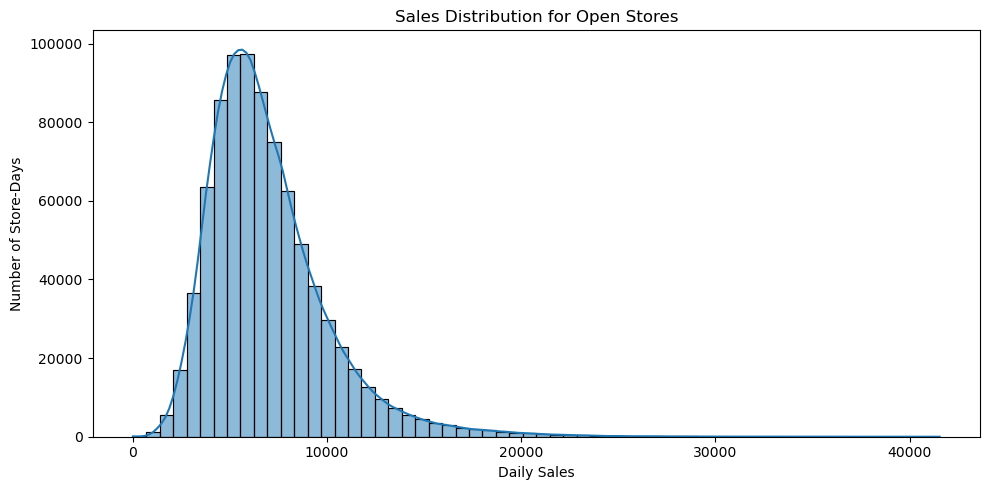

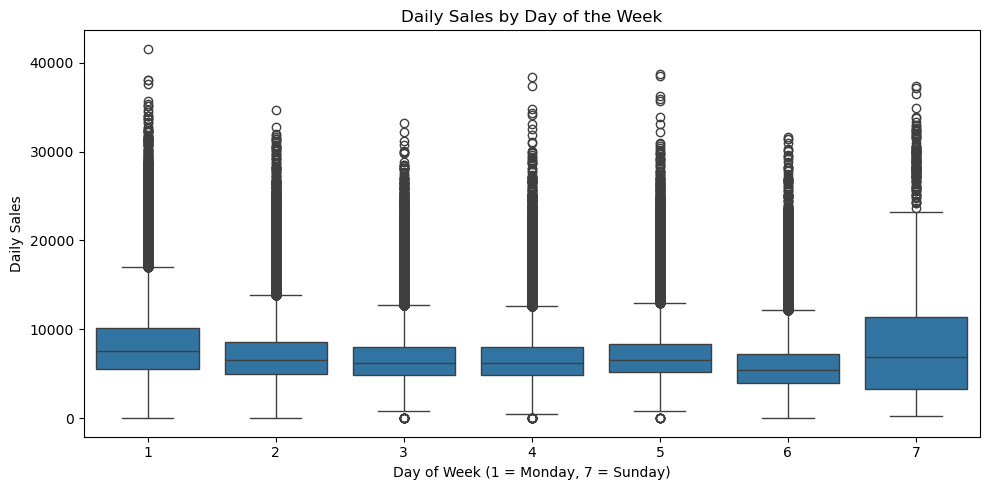

Sales by promotion status (open stores only):


,mean,median,count
Promo,,,
No Promotion,5929.407603,5459.0,467496
Promotion,8228.281239,7649.0,376896


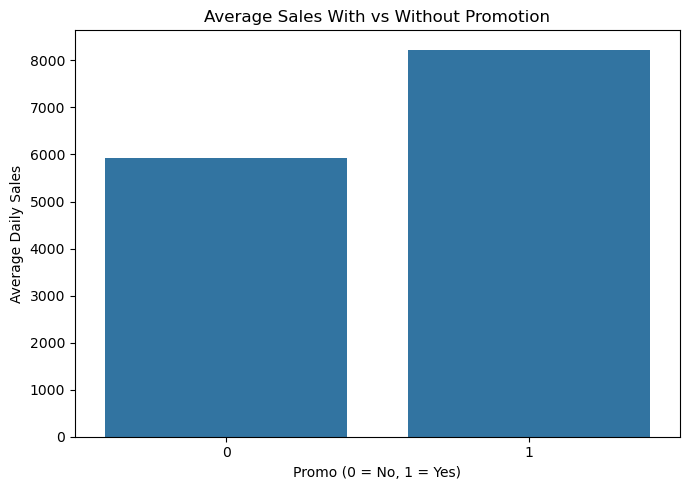

In [17]:

# Use only open stores for demand-focused comparisons
open_train = train_clean[train_clean["Open"] == 1].copy()

# 1. Sales distribution among open stores
plt.figure(figsize=(10, 5))
sns.histplot(open_train["Sales"], bins=60, kde=True)
plt.title("Sales Distribution for Open Stores")
plt.xlabel("Daily Sales")
plt.ylabel("Number of Store-Days")
plt.tight_layout()
plt.show()

# 2. Sales by day of the week
plt.figure(figsize=(10, 5))
sns.boxplot(data=open_train, x="DayOfWeek", y="Sales")
plt.title("Daily Sales by Day of the Week")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Daily Sales")
plt.tight_layout()
plt.show()

# 3. Average sales with and without promotions
promo_sales = (
    open_train.groupby("Promo")["Sales"]
    .agg(["mean", "median", "count"])
    .rename(index={0: "No Promotion", 1: "Promotion"})
)

print("Sales by promotion status (open stores only):")
display(promo_sales)

plt.figure(figsize=(7, 5))
sns.barplot(data=open_train, x="Promo", y="Sales", errorbar=None)
plt.title("Average Sales With vs Without Promotion")
plt.xlabel("Promo (0 = No, 1 = Yes)")
plt.ylabel("Average Daily Sales")
plt.tight_layout()
plt.show()

In [18]:
# Compare promotion performance across stores
store_promo = (
    open_train.groupby(["Store", "Promo"])
    .agg(
        AvgSales=("Sales", "mean"),
        AvgCustomers=("Customers", "mean"),
        Days=("Sales", "size")
    )
    .reset_index()
)

# Separate promotion and non-promotion results
promo_comparison = store_promo.pivot(
    index="Store",
    columns="Promo",
    values=["AvgSales", "AvgCustomers"]
)

promo_comparison.columns = [
    f"{metric}_{'NoPromo' if promo == 0 else 'Promo'}"
    for metric, promo in promo_comparison.columns
]

promo_comparison = promo_comparison.dropna().copy()

promo_comparison["SalesChangePct"] = (
    (promo_comparison["AvgSales_Promo"] -
     promo_comparison["AvgSales_NoPromo"])
    / promo_comparison["AvgSales_NoPromo"].replace(0, float("nan"))
) * 100

promo_comparison["CustomerChangePct"] = (
    (promo_comparison["AvgCustomers_Promo"] -
     promo_comparison["AvgCustomers_NoPromo"])
    / promo_comparison["AvgCustomers_NoPromo"].replace(0, float("nan"))
) * 100

print("Stores with the largest sales increases during promotions:")
display(promo_comparison.nlargest(10, "SalesChangePct"))

print("\nStores with the smallest sales changes during promotions:")
display(promo_comparison.nsmallest(10, "SalesChangePct"))

print("\nOverall average percentage change:")
print(promo_comparison[["SalesChangePct", "CustomerChangePct"]].mean().round(2))

Stores with the largest sales increases during promotions:


,AvgSales_NoPromo,AvgSales_Promo,AvgCustomers_NoPromo,AvgCustomers_Promo,SalesChangePct,CustomerChangePct
Store,,,,,,
198,1753.461538,4294.725212,242.778555,454.781870,144.928396,87.323740
607,2551.573427,5542.971671,310.526807,539.917847,117.237396,73.871574
543,1868.129930,3926.065714,189.222738,302.937143,110.160206,60.095529
575,3614.405172,7586.112727,378.413793,637.905455,109.885510,68.573521
693,4577.874710,9107.817143,388.709977,624.848571,98.952958,60.749301
271,5452.700935,10746.485795,614.724299,1007.241477,97.085553,63.852556
552,5412.452436,10565.745714,560.060325,849.780000,95.211798,51.730084
96,3638.345794,7047.616477,426.453271,684.210227,93.703866,60.442016
635,4159.048951,8048.373219,464.545455,758.259259,93.514751,63.226064



Stores with the smallest sales changes during promotions:


,AvgSales_NoPromo,AvgSales_Promo,AvgCustomers_NoPromo,AvgCustomers_Promo,SalesChangePct,CustomerChangePct
Store,,,,,,
274,4182.435540,3891.882682,1011.128920,963.259777,-6.946978,-4.734227
262,20549.637457,20991.536111,3446.417526,3330.219444,2.150396,-3.371561
948,6865.652705,7051.535211,1666.301920,1786.878873,2.707427,7.236201
827,12587.897674,12995.518414,1693.788372,1626.475921,3.238196,-3.974077
553,6928.909091,7173.818966,660.226107,612.267241,3.534609,-7.264006
353,5549.949565,5799.303371,1418.257391,1500.033708,4.492902,5.765971
444,11917.105140,12521.787966,1464.355140,1372.553009,5.074075,-6.269117
760,7458.172897,7859.343840,1226.710280,1227.902579,5.378944,0.097195
676,7529.674256,7947.112392,1628.726795,1784.461095,5.543907,9.561720



Overall average percentage change:
SalesChangePct       41.43
CustomerChangePct    23.84
dtype: float64


In [19]:
# Compare sales and customers by holiday type
holiday_summary = (
    open_train.groupby(["StateHoliday", "SchoolHoliday"])
    .agg(
        AvgSales=("Sales", "mean"),
        MedianSales=("Sales", "median"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .reset_index()
)

print("Sales and customer behavior by holiday status:")
display(holiday_summary)

# Compare state holiday categories
state_holiday_summary = (
    open_train.groupby("StateHoliday")
    .agg(
        AvgSales=("Sales", "mean"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .reset_index()
)

print("\nBy state holiday:")
display(state_holiday_summary)

# Compare school holiday status
school_holiday_summary = (
    open_train.groupby("SchoolHoliday")
    .agg(
        AvgSales=("Sales", "mean"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .reset_index()
)

print("\nBy school holiday:")
display(school_holiday_summary)


Sales and customer behavior by holiday status:


,StateHoliday,SchoolHoliday,AvgSales,MedianSales,AvgCustomers,StoreDays
0,0,0,6566.903037,6032.0,741.940342,82856
1,0,1,7082.297774,6531.5,775.068297,29284
2,0,0,6940.673135,6365.0,759.491832,597483
3,0,1,7221.966659,6566.0,783.236301,133859
4,a,0,8492.066102,7624.5,1266.113559,590
5,a,1,8461.403846,6897.5,1353.259615,104
6,b,0,34781.166667,34782.0,5076.166667,6
7,b,1,8813.359712,8174.0,1540.589928,139
8,c,1,9743.746479,8397.0,1569.225352,71



By state holiday:


,StateHoliday,AvgSales,AvgCustomers,StoreDays
0,0,6701.492117,750.591306,112140
1,0,6992.158856,763.837830,731342
2,a,8487.471182,1279.172911,694
3,b,9887.889655,1686.889655,145
4,c,9743.746479,1569.225352,71



By school holiday:


,SchoolHoliday,AvgSales,AvgCustomers,StoreDays
0,0,6896.782411,757.833172,680935
1,1,7200.181650,783.121090,163457


,Month,AvgSales,AvgCustomers,StoreDays
0,1,6563.690444,722.514749,86343
1,2,6589.165535,731.504792,80243
2,3,6976.412026,759.081600,85980
3,4,7046.228420,774.271806,81731
4,5,7106.453154,779.290214,80103
5,6,7000.978190,759.277357,82576
6,7,6952.682125,752.745522,85587
7,8,6648.984654,750.384706,54413
8,9,6546.343035,745.613988,52330
9,10,6602.843354,752.573557,53292


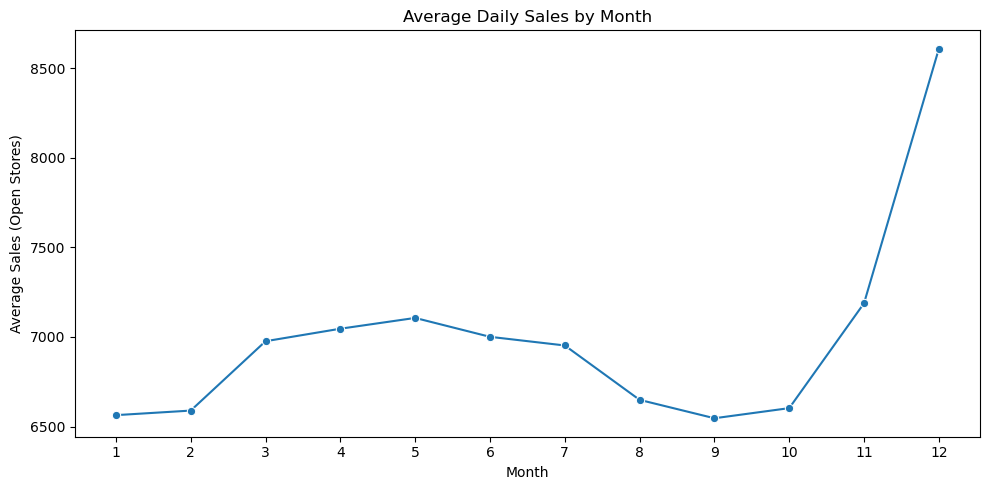

State-holiday summary by year:


,Year,HolidayType,AvgSales,AvgCustomers,StoreDays
0,2013,a,7863.632184,1190.302682,261
1,2013,b,9680.787234,1646.148936,47
2,2013,c,9199.500000,1521.777778,36
3,2014,a,8685.900000,1338.916667,240
4,2014,b,9456.183673,1666.489796,49
5,2014,c,10303.542857,1618.028571,35
6,2015,a,9084.357513,1325.062176,193
7,2015,b,10518.244898,1746.367347,49


In [20]:
# Extract date features for EDA
open_train["Date"] = pd.to_datetime(open_train["Date"])
open_train["Year"] = open_train["Date"].dt.year
open_train["Month"] = open_train["Date"].dt.month

# Average sales by month
monthly_sales = (
    open_train.groupby("Month")
    .agg(
        AvgSales=("Sales", "mean"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .reset_index()
)

display(monthly_sales)

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x="Month", y="AvgSales", marker="o")
plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales (Open Stores)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# Examine state-holiday records by year and date
holiday_rows = open_train[
    open_train["StateHoliday"].astype(str).str.strip().isin(["a", "b", "c"])
].copy()

holiday_rows["HolidayType"] = holiday_rows["StateHoliday"].astype(str).str.strip()

holiday_period_summary = (
    holiday_rows.groupby(["Year", "HolidayType"])
    .agg(
        AvgSales=("Sales", "mean"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .reset_index()
)

print("State-holiday summary by year:")
display(holiday_period_summary)

In [23]:
store_info = pd.read_csv("Z:/Projec _ Internship/Proj_6/data/store.csv")

print("Store information shape:", store_info.shape)
print("\nColumns:")
print(store_info.columns.tolist())

print("\nMissing values:")
print(store_info.isna().sum())

display(store_info.head())

Store information shape: (1115, 10)

Columns:
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

Missing values:
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [24]:
# Merge store metadata into the training data
open_store_train = (
    train_clean[train_clean["Open"] == 1]
    .merge(store_info, on="Store", how="left", validate="many_to_one")
)

print("Merged shape:", open_store_train.shape)
print("Rows without store metadata:", open_store_train["StoreType"].isna().sum())

# 1. Average sales by store type
sales_by_type = (
    open_store_train.groupby("StoreType")
    .agg(
        AvgSales=("Sales", "mean"),
        MedianSales=("Sales", "median"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .round(2)
)

print("\nAverage sales by store type:")
display(sales_by_type)

# 2. Average sales by assortment
sales_by_assortment = (
    open_store_train.groupby("Assortment")
    .agg(
        AvgSales=("Sales", "mean"),
        MedianSales=("Sales", "median"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .round(2)
)

print("\nAverage sales by assortment:")
display(sales_by_assortment)

# 3. Store type and assortment together
type_assortment = (
    open_store_train.groupby(["StoreType", "Assortment"])
    .agg(
        AvgSales=("Sales", "mean"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .round(2)
)

print("\nStore type + assortment:")
display(type_assortment)

# 4. Compare stores with and without Promo2
promo2_comparison = (
    open_store_train.groupby("Promo2")
    .agg(
        AvgSales=("Sales", "mean"),
        MedianSales=("Sales", "median"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size"),
        NumberOfStores=("Store", "nunique")
    )
    .round(2)
)

print("\nPromo2 comparison (0 = no continuing promotion, 1 = participates):")
display(promo2_comparison)

# 5. Competition distance and sales
distance_bins = [0, 500, 2000, 5000, 10000, np.inf]
distance_labels = [
    "0–500 m",
    "501–2,000 m",
    "2,001–5,000 m",
    "5,001–10,000 m",
    "Over 10,000 m"
]

open_store_train["CompetitionDistanceGroup"] = pd.cut(
    open_store_train["CompetitionDistance"],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True
)

competition_comparison = (
    open_store_train.groupby("CompetitionDistanceGroup", observed=False)
    .agg(
        AvgSales=("Sales", "mean"),
        MedianSales=("Sales", "median"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size"),
        NumberOfStores=("Store", "nunique")
    )
    .round(2)
)

print("\nSales by competition distance:")
display(competition_comparison)

# 6. Check whether missing Promo2 details correspond to Promo2 = 0
print("\nPromo2 metadata consistency:")
display(
    store_info.groupby("Promo2")
    .agg(
        NumberOfStores=("Store", "count"),
        MissingPromoWeek=("Promo2SinceWeek", lambda s: s.isna().sum()),
        MissingPromoYear=("Promo2SinceYear", lambda s: s.isna().sum()),
        MissingPromoInterval=("PromoInterval", lambda s: s.isna().sum())
    )
)

Merged shape: (844392, 18)
Rows without store metadata: 0

Average sales by store type:


,AvgSales,MedianSales,AvgCustomers,StoreDays
StoreType,,,,
a,6925.17,6285.0,795.36,457077
b,10231.41,9130.0,2021.82,15563
c,6932.51,6407.0,815.47,112978
d,6822.14,6395.0,606.34,258774



Average sales by assortment:


,AvgSales,MedianSales,AvgCustomers,StoreDays
Assortment,,,,
a,6621.02,6082.0,747.94,444909
b,8639.35,8081.0,2066.80,8212
c,7300.53,6675.0,752.17,391271



Store type + assortment:


AvgSales  AvgCustomers  StoreDays
StoreType Assortment                                   
a         a            6537.62        759.24     286053
          c            7573.38        855.77     171024
b         a           11133.99       1804.98       6409
          b            8639.35       2066.80       8212
          c           17969.56       3105.05        942
c         a            6834.93        839.86      58561
          c            7037.53        789.21      54417
d         a            6433.62        584.02      93886
          c            7043.36        619.05     164888

... (2 outputs left out)


Sales by competition distance:


,AvgSales,MedianSales,AvgCustomers,StoreDays,NumberOfStores
CompetitionDistanceGroup,,,,,
0–500 m,7609.90,6790.0,968.55,168108,220
"501–2,000 m",6919.90,6207.0,812.80,212693,282
"2,001–5,000 m",6678.16,6248.0,691.95,196883,261
"5,001–10,000 m",6742.59,6342.0,629.90,121911,162
"Over 10,000 m",6824.76,6378.0,659.92,142611,187



Promo2 metadata consistency:


,NumberOfStores,MissingPromoWeek,MissingPromoYear,MissingPromoInterval
Promo2,,,,
0,544,544,544,544
1,571,0,0,0


In [25]:
type_assortment = (
    open_store_train
    .groupby(["StoreType", "Assortment"], observed=True)
    .agg(
        AvgSales=("Sales", "mean"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size"),
        NumberOfStores=("Store", "nunique")
    )
    .reset_index()
    .sort_values("AvgSales", ascending=False)
    .round(2)
)

display(type_assortment)

,StoreType,Assortment,AvgSales,AvgCustomers,StoreDays,NumberOfStores
4,b,c,17969.56,3105.05,942,1
2,b,a,11133.99,1804.98,6409,7
3,b,b,8639.35,2066.80,8212,9
1,a,c,7573.38,855.77,171024,221
8,d,c,7043.36,619.05,164888,220
6,c,c,7037.53,789.21,54417,71
5,c,a,6834.93,839.86,58561,77
0,a,a,6537.62,759.24,286053,381
7,d,a,6433.62,584.02,93886,128


In [26]:
# Check stores with missing competition distance
print("Stores with missing competition distance:")
display(
    store_info.loc[
        store_info["CompetitionDistance"].isna(),
        ["Store", "StoreType", "Assortment",
         "CompetitionDistance",
         "CompetitionOpenSinceMonth",
         "CompetitionOpenSinceYear"]
    ]
)

# Calculate store-level average sales
store_sales = (
    open_store_train
    .groupby("Store")
    .agg(
        AvgSales=("Sales", "mean"),
        AvgCustomers=("Customers", "mean"),
        StoreDays=("Sales", "size")
    )
    .reset_index()
    .merge(store_info, on="Store", how="left", validate="one_to_one")
)

print("\nStore-level correlation with competition distance:")
print(
    store_sales[
        ["AvgSales", "AvgCustomers", "CompetitionDistance"]
    ].corr().round(3)
)

# Compare average store-level sales by competition-distance group
store_sales["CompetitionDistanceGroup"] = pd.cut(
    store_sales["CompetitionDistance"],
    bins=[0, 500, 2000, 5000, 10000, float("inf")],
    labels=[
        "0–500 m",
        "501–2,000 m",
        "2,001–5,000 m",
        "5,001–10,000 m",
        "Over 10,000 m"
    ],
    include_lowest=True
)

display(
    store_sales.groupby("CompetitionDistanceGroup", observed=True)
    .agg(
        AvgStoreSales=("AvgSales", "mean"),
        MedianStoreSales=("AvgSales", "median"),
        NumberOfStores=("Store", "nunique")
    )
    .round(2)
)

Stores with missing competition distance:


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear
290,291,d,a,NaN,NaN,NaN
621,622,a,c,NaN,NaN,NaN
878,879,d,a,NaN,NaN,NaN



Store-level correlation with competition distance:
                     AvgSales  AvgCustomers  CompetitionDistance
AvgSales                1.000         0.830               -0.042
AvgCustomers            0.830         1.000               -0.162
CompetitionDistance    -0.042        -0.162                1.000


,AvgStoreSales,MedianStoreSales,NumberOfStores
CompetitionDistanceGroup,,,
0–500 m,7581.49,7016.61,220
"501–2,000 m",6873.24,6216.97,282
"2,001–5,000 m",6675.97,6464.92,261
"5,001–10,000 m",6724.84,6597.95,162
"Over 10,000 m",6831.57,6675.29,187


In [27]:
# Prepare modeling copies
model_train = train_clean.copy()
model_test = test_clean.copy()

# Normalize holiday categories to strings
model_train["StateHoliday"] = (
    model_train["StateHoliday"].astype(str).replace({"0.0": "0"})
)
model_test["StateHoliday"] = (
    model_test["StateHoliday"].astype(str).replace({"0.0": "0"})
)

# Merge store metadata
model_train = model_train.merge(
    store_info, on="Store", how="left", validate="many_to_one"
)
model_test = model_test.merge(
    store_info, on="Store", how="left", validate="many_to_one"
)

# Date-based feature engineering
def add_date_features(df):
    df = df.copy()
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Day"] = df["Date"].dt.day
    df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)
    df["IsWeekend"] = df["DayOfWeek"].isin([6, 7]).astype(int)
    df["IsMonthStart"] = df["Date"].dt.is_month_start.astype(int)
    df["IsMonthEnd"] = df["Date"].dt.is_month_end.astype(int)
    return df

model_train = add_date_features(model_train)
model_test = add_date_features(model_test)

print("Training shape:", model_train.shape)
print("Test shape:", model_test.shape)

print("\nTraining date range:")
print(model_train["Date"].min(), "to", model_train["Date"].max())

print("\nTest date range:")
print(model_test["Date"].min(), "to", model_test["Date"].max())

print("\nMissing values in competition distance:")
print("Train:", model_train["CompetitionDistance"].isna().sum())
print("Test:", model_test["CompetitionDistance"].isna().sum())

print("\nTraining target summary:")
print(model_train["Sales"].describe())

Training shape: (1017209, 25)
Test shape: (41088, 25)

Training date range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Test date range:
2015-08-01 00:00:00 to 2015-09-17 00:00:00

Missing values in competition distance:
Train: 2642
Test: 96

Training target summary:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64


In [28]:
model_data = model_train.loc[
    (model_train["Open"] == 1) & (model_train["Sales"] > 0)
].copy()

# 2. Chronological split
validation_start = pd.Timestamp("2015-06-01")

train_part = model_data[model_data["Date"] < validation_start].copy()
valid_part = model_data[model_data["Date"] >= validation_start].copy()

# 3. Select features available at prediction time
numeric_features = [
    "Store",
    "DayOfWeek",
    "Promo",
    "SchoolHoliday",
    "CompetitionDistance",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2",
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "Year",
    "Month",
    "Day",
    "WeekOfYear",
    "IsWeekend",
    "IsMonthStart",
    "IsMonthEnd"
]

categorical_features = [
    "StoreType",
    "Assortment",
    "StateHoliday",
    "PromoInterval"
]

features = numeric_features + categorical_features
target = "Sales"

X_train = train_part[features]
y_train = train_part[target]

X_valid = valid_part[features]
y_valid = valid_part[target]

# 4. Preprocessing inside the pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 5. Baseline random forest
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=80,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

baseline_model.fit(X_train, y_train)

valid_predictions = baseline_model.predict(X_valid)
valid_predictions = np.maximum(valid_predictions, 0)

mae = mean_absolute_error(y_valid, valid_predictions)
rmse = np.sqrt(mean_squared_error(y_valid, valid_predictions))

print("\nBaseline validation results")
print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")


Training rows: 785727
Validation rows: 58611

Baseline validation results
MAE:  710.71
RMSE: 1,056.97


In [29]:
# Predict each validation store's average sales from the training period
store_mean_sales = train_part.groupby("Store")["Sales"].mean()

benchmark_predictions = (
    X_valid["Store"]
    .map(store_mean_sales)
    .fillna(y_train.mean())
    .to_numpy()
)

benchmark_mae = mean_absolute_error(y_valid, benchmark_predictions)
benchmark_rmse = np.sqrt(
    mean_squared_error(y_valid, benchmark_predictions)
)

print("Store-average benchmark")
print(f"MAE:  {benchmark_mae:,.2f}")
print(f"RMSE: {benchmark_rmse:,.2f}")

print("\nRandom Forest baseline")
print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")

print("\nImprovement in MAE:")
print(
    f"{(benchmark_mae - mae) / benchmark_mae * 100:.2f}%"
)

Store-average benchmark
MAE:  1,486.65
RMSE: 1,979.55

Random Forest baseline
MAE:  710.71
RMSE: 1,056.97

Improvement in MAE:
52.19%


In [30]:
# Examine a sample of actual and predicted sales
validation_results = valid_part[
    ["Store", "Date", "Sales", "Promo", "DayOfWeek"]
].copy()

validation_results["PredictedSales"] = valid_predictions
validation_results["AbsoluteError"] = (
    validation_results["Sales"]
    - validation_results["PredictedSales"]
).abs()

print("Largest prediction errors:")
display(
    validation_results
    .sort_values("AbsoluteError", ascending=False)
    .head(10)
)

print("\nError by promotion status:")
display(
    validation_results.groupby("Promo")
    .agg(
        MAE=("AbsoluteError", "mean"),
        ActualSales=("Sales", "mean"),
        PredictedSales=("PredictedSales", "mean"),
        Rows=("Sales", "size")
    )
    .round(2)
)

Largest prediction errors:


,Store,Date,Sales,Promo,DayOfWeek,PredictedSales,AbsoluteError
44393,909,2015-06-22,41551,0,1,9049.017707,32501.982293
43278,909,2015-06-23,30038,0,2,8998.036650,21039.963350
35971,292,2015-06-29,29161,1,1,8210.019220,20950.980780
28750,876,2015-07-06,27330,0,1,8344.904909,18985.095091
34856,292,2015-06-30,23584,1,2,7415.610902,16168.389098
27635,876,2015-07-07,23927,0,2,9018.991226,14908.008774
13173,909,2015-07-20,23081,0,1,9098.293315,13982.706685
46623,909,2015-06-20,22882,0,6,10093.428899,12788.571101
26520,876,2015-07-08,19665,0,3,8044.530433,11620.469567
67082,183,2015-06-01,18797,1,1,7304.649882,11492.350118



Error by promotion status:


,MAE,ActualSales,PredictedSales,Rows
Promo,,,,
0,566.39,5936.36,6168.52,31449
1,877.81,8577.92,8510.20,27162


In [31]:
# 1. Store-average benchmark
store_mean_sales = train_part.groupby("Store")["Sales"].mean()

benchmark_predictions = (
    X_valid["Store"]
    .map(store_mean_sales)
    .fillna(y_train.mean())
    .to_numpy()
)

benchmark_mae = mean_absolute_error(y_valid, benchmark_predictions)
benchmark_rmse = np.sqrt(
    mean_squared_error(y_valid, benchmark_predictions)
)

print("Store-average benchmark")
print(f"MAE:  {benchmark_mae:,.2f}")
print(f"RMSE: {benchmark_rmse:,.2f}")

print("\nRandom Forest baseline")
print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")

print(f"\nMAE improvement: {(benchmark_mae - mae) / benchmark_mae * 100:.2f}%")

# 2. Error analysis
validation_results = valid_part[
    ["Store", "Date", "Sales", "Promo", "DayOfWeek"]
].copy()

validation_results["PredictedSales"] = valid_predictions
validation_results["AbsoluteError"] = (
    validation_results["Sales"] - validation_results["PredictedSales"]
).abs()

print("\nLargest prediction errors:")
display(
    validation_results
    .sort_values("AbsoluteError", ascending=False)
    .head(10)
)

print("\nError by promotion status:")
display(
    validation_results.groupby("Promo")
    .agg(
        MAE=("AbsoluteError", "mean"),
        ActualSales=("Sales", "mean"),
        PredictedSales=("PredictedSales", "mean"),
        Rows=("Sales", "size")
    )
    .round(2)
)

Store-average benchmark
MAE:  1,486.65
RMSE: 1,979.55

Random Forest baseline
MAE:  710.71
RMSE: 1,056.97

MAE improvement: 52.19%

Largest prediction errors:


,Store,Date,Sales,Promo,DayOfWeek,PredictedSales,AbsoluteError
44393,909,2015-06-22,41551,0,1,9049.017707,32501.982293
43278,909,2015-06-23,30038,0,2,8998.036650,21039.963350
35971,292,2015-06-29,29161,1,1,8210.019220,20950.980780
28750,876,2015-07-06,27330,0,1,8344.904909,18985.095091
34856,292,2015-06-30,23584,1,2,7415.610902,16168.389098
27635,876,2015-07-07,23927,0,2,9018.991226,14908.008774
13173,909,2015-07-20,23081,0,1,9098.293315,13982.706685
46623,909,2015-06-20,22882,0,6,10093.428899,12788.571101
26520,876,2015-07-08,19665,0,3,8044.530433,11620.469567
67082,183,2015-06-01,18797,1,1,7304.649882,11492.350118



Error by promotion status:


,MAE,ActualSales,PredictedSales,Rows
Promo,,,,
0,566.39,5936.36,6168.52,31449
1,877.81,8577.92,8510.20,27162


In [32]:
feature_names = (
    baseline_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Random Forest feature importance values
importances = (
    baseline_model
    .named_steps["regressor"]
    .feature_importances_
)

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 features:")
display(feature_importance.head(20))

Top 20 features:


,Feature,Importance
0,numeric__CompetitionDistance,0.196925
1,numeric__Store,0.156123
2,numeric__Promo,0.141468
3,numeric__CompetitionOpenSinceYear,0.084872
4,numeric__CompetitionOpenSinceMonth,0.072631
5,numeric__DayOfWeek,0.056787
6,numeric__WeekOfYear,0.035489
7,numeric__Promo2SinceWeek,0.033271
8,numeric__Day,0.029000
9,categorical__StoreType_b,0.027020


In [33]:
example = pd.DataFrame({
    "Store": [1, 2, 3, 4],
    "Promo": [1, 0, 1, 0],
    "Sales": [8000, 4000, 9000, 5000]
})

print("Original data:")
display(example)

# Shuffle only Promo values
example_shuffled = example.copy()

example_shuffled["Promo"] = (
    example_shuffled["Promo"]
    .sample(frac=1, random_state=42)
    .to_numpy()
)

print("After shuffling Promo:")
display(example_shuffled)

Original data:


,Store,Promo,Sales
0,1,1,8000
1,2,0,4000
2,3,1,9000
3,4,0,5000


After shuffling Promo:


,Store,Promo,Sales
0,1,0,8000
1,2,0,4000
2,3,1,9000
3,4,1,5000


In [34]:

# Use a sample of the validation data
X_valid_sample = X_valid.sample(
    n=10000,
    random_state=42
)

y_valid_sample = y_valid.loc[X_valid_sample.index]

# Calculate permutation importance
permutation_result = permutation_importance(
    baseline_model,
    X_valid_sample,
    y_valid_sample,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

# Organize the results
permutation_importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(permutation_importance_df.head(15))

,Feature,Importance,Std
0,CompetitionDistance,1205.202114,5.638074
1,Assortment,793.777721,4.482828
2,Promo,704.397979,5.628359
3,Store,674.416044,4.106330
4,CompetitionOpenSinceMonth,513.379588,1.059456
5,Promo2,481.669206,5.103525
6,StoreType,413.887259,3.260468
7,CompetitionOpenSinceYear,397.274762,1.251773
8,Promo2SinceYear,332.334149,3.022948
9,DayOfWeek,295.409698,10.415401


In [35]:
# Create a separate copy for lag-feature experiments
lag_data = model_train.copy()

# Keep only open stores for this first sales model
lag_data = lag_data[lag_data["Open"] == 1].copy()

# Ensure data is sorted chronologically within each store
lag_data = lag_data.sort_values(["Store", "Date"])

# Previous week's sales for the same store
lag_data["SalesLag7"] = (
    lag_data.groupby("Store")["Sales"]
    .shift(7)
)

# Inspect a single store to understand the lag
display(
    lag_data.loc[
        lag_data["Store"] == 1,
        ["Store", "Date", "Sales", "SalesLag7"]
    ].head(15)
)

print("Missing SalesLag7 values:", lag_data["SalesLag7"].isna().sum())

,Store,Date,Sales,SalesLag7
1014980,1,2013-01-02,5530,NaN
1013865,1,2013-01-03,4327,NaN
1012750,1,2013-01-04,4486,NaN
1011635,1,2013-01-05,4997,NaN
1009405,1,2013-01-07,7176,NaN
1008290,1,2013-01-08,5580,NaN
1007175,1,2013-01-09,5471,NaN
1006060,1,2013-01-10,4892,5530.0
1004945,1,2013-01-11,4881,4327.0
1003830,1,2013-01-12,4952,4486.0


Missing SalesLag7 values: 7805


In [36]:
# Use the full training data, including closed-store days
sales_history = model_train[["Store", "Date", "Sales"]].copy()

# Make a lookup table for historical sales
lag_lookup = sales_history.rename(
    columns={
        "Date": "LagDate",
        "Sales": "SalesLag7"
    }
)

# For each row, find sales from exactly 7 calendar days earlier
lag_data = model_train.copy()

lag_data["LagDate"] = (
    lag_data["Date"] - pd.Timedelta(days=7)
)

lag_data = lag_data.merge(
    lag_lookup,
    on=["Store", "LagDate"],
    how="left",
    validate="many_to_one"
)

# Inspect the result
print("Missing SalesLag7 values:", lag_data["SalesLag7"].isna().sum())

display(
    lag_data[
        ["Store", "Date", "Sales", "LagDate", "SalesLag7"]
    ].head(15)
)

Missing SalesLag7 values: 9065


,Store,Date,Sales,LagDate,SalesLag7
0,1,2015-07-31,5263,2015-07-24,3706.0
1,2,2015-07-31,6064,2015-07-24,3854.0
2,3,2015-07-31,8314,2015-07-24,5080.0
3,4,2015-07-31,13995,2015-07-24,8322.0
4,5,2015-07-31,4822,2015-07-24,3815.0
5,6,2015-07-31,5651,2015-07-24,3804.0
6,7,2015-07-31,15344,2015-07-24,9203.0
7,8,2015-07-31,8492,2015-07-24,4917.0
8,9,2015-07-31,8565,2015-07-24,5464.0
9,10,2015-07-31,7185,2015-07-24,6152.0


In [37]:
# Keep open stores with positive sales, as in our baseline
lag_model_data = lag_data.loc[
    (lag_data["Open"] == 1) &
    (lag_data["Sales"] > 0)
].copy()

# Time-based validation split
validation_start = pd.Timestamp("2015-06-01")

lag_train_part = lag_model_data[
    lag_model_data["Date"] < validation_start
].copy()

lag_valid_part = lag_model_data[
    lag_model_data["Date"] >= validation_start
].copy()

# Add SalesLag7 to the numeric features
lag_numeric_features = numeric_features + ["SalesLag7"]

lag_features = lag_numeric_features + categorical_features

X_lag_train = lag_train_part[lag_features]
y_lag_train = lag_train_part["Sales"]

X_lag_valid = lag_valid_part[lag_features]
y_lag_valid = lag_valid_part["Sales"]

# Reuse our preprocessing pipelines
lag_preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        lag_numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

lag_model = Pipeline([
    ("preprocessor", lag_preprocessor),
    (
        "regressor",
        RandomForestRegressor(
            n_estimators=80,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

lag_model.fit(X_lag_train, y_lag_train)

lag_valid_predictions = np.maximum(
    lag_model.predict(X_lag_valid),
    0
)

lag_mae = mean_absolute_error(
    y_lag_valid,
    lag_valid_predictions
)

lag_rmse = np.sqrt(
    mean_squared_error(
        y_lag_valid,
        lag_valid_predictions
    )
)

print(f"Lag Model MAE:  {lag_mae:.2f}")
print(f"Lag Model RMSE: {lag_rmse:.2f}")

Lag Model MAE:  1038.29
Lag Model RMSE: 1494.03


In [38]:
# Compare validation errors by month
baseline_errors = lag_valid_part[["Date", "Sales"]].copy()

baseline_errors["BaselinePrediction"] = valid_predictions
baseline_errors["LagPrediction"] = lag_valid_predictions

baseline_errors["BaselineAbsError"] = (
    baseline_errors["Sales"] -
    baseline_errors["BaselinePrediction"]
).abs()

baseline_errors["LagAbsError"] = (
    baseline_errors["Sales"] -
    baseline_errors["LagPrediction"]
).abs()

baseline_errors["Month"] = baseline_errors["Date"].dt.to_period("M")

monthly_comparison = baseline_errors.groupby("Month").agg(
    Baseline_MAE=("BaselineAbsError", "mean"),
    Lag_MAE=("LagAbsError", "mean"),
    Rows=("Sales", "count")
).reset_index()

display(monthly_comparison)


,Month,Baseline_MAE,Lag_MAE,Rows
0,2015-06,675.689273,991.378678,28423
1,2015-07,743.678277,1082.453032,30188


In [39]:


# Reuse the existing X_train, X_valid, y_train, y_valid
# and the numeric_features / categorical_features lists.

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=80,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

results = []

for model_name, regressor in models.items():

    # HistGradientBoosting requires dense numeric input.
    # The other models can use the standard preprocessing pipeline.
    if model_name == "HistGradientBoosting":
        hgb_numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ])

        hgb_categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ])

        hgb_preprocessor = ColumnTransformer([
            ("numeric", hgb_numeric_pipeline, numeric_features),
            ("categorical", hgb_categorical_pipeline, categorical_features)
        ])

    else:
        hgb_preprocessor = preprocessor

    model_pipeline = Pipeline([
        ("preprocessor", hgb_preprocessor),
        ("regressor", regressor)
    ])

    print(f"Training {model_name}...")

    model_pipeline.fit(X_train, y_train)

    predictions = np.maximum(
        model_pipeline.predict(X_valid),
        0
    )

    mae = mean_absolute_error(y_valid, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_valid, predictions)
    )

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

    print(f"{model_name} | MAE: {mae:.2f} | RMSE: {rmse:.2f}")

model_comparison = pd.DataFrame(results).sort_values("MAE")

display(model_comparison)

Training Random Forest...
Random Forest | MAE: 710.71 | RMSE: 1056.97
Training Extra Trees...
Extra Trees | MAE: 707.40 | RMSE: 1015.35
Training HistGradientBoosting...


c:\Users\Sidd\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Sidd\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Sidd\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Sidd\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

HistGradientBoosting | MAE: 1163.62 | RMSE: 1578.96


,Model,MAE,RMSE
1,Extra Trees,707.402910,1015.350342
0,Random Forest,710.707479,1056.973436
2,HistGradientBoosting,1163.618494,1578.957892


In [40]:
et_configs = [
    {
        "name": "Extra Trees - Baseline",
        "n_estimators": 100,
        "min_samples_leaf": 5,
        "max_features": 1.0
    },
    {
        "name": "Extra Trees - More Trees",
        "n_estimators": 200,
        "min_samples_leaf": 5,
        "max_features": 1.0
    },
    {
        "name": "Extra Trees - Larger Leaves",
        "n_estimators": 100,
        "min_samples_leaf": 10,
        "max_features": 1.0
    },
    {
        "name": "Extra Trees - Feature Sampling",
        "n_estimators": 100,
        "min_samples_leaf": 5,
        "max_features": 0.8
    }
]

et_results = []
et_models = {}

for config in et_configs:

    model_name = config["name"]

    et_regressor = ExtraTreesRegressor(
        n_estimators=config["n_estimators"],
        min_samples_leaf=config["min_samples_leaf"],
        max_features=config["max_features"],
        random_state=42,
        n_jobs=-1
    )

    et_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", et_regressor)
    ])

    print(f"Training {model_name}...")

    et_pipeline.fit(X_train, y_train)

    predictions = np.maximum(
        et_pipeline.predict(X_valid),
        0
    )

    mae = mean_absolute_error(y_valid, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_valid, predictions)
    )

    et_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

    et_models[model_name] = et_pipeline

et_comparison = pd.DataFrame(et_results).sort_values("MAE")

display(et_comparison)

Training Extra Trees - Baseline...
Training Extra Trees - More Trees...
Training Extra Trees - Larger Leaves...
Training Extra Trees - Feature Sampling...


,Model,MAE,RMSE
3,Extra Trees - Feature Sampling,705.138084,1021.688696
2,Extra Trees - Larger Leaves,705.941143,1047.881693
1,Extra Trees - More Trees,707.292338,1015.152873
0,Extra Trees - Baseline,707.402910,1015.350342


In [41]:
best_et_config = {
    "n_estimators": 100,
    "min_samples_leaf": 5,
    "max_features": 0.8,
    "random_state": 42,
    "n_jobs": -1
}

In [42]:
# Check whether TensorFlow is available
try:
    import tensorflow as tf
    print("TensorFlow version:", tf.__version__)
except ImportError:
    print("TensorFlow is not installed.")

# Inspect daily sales for one store
store_id = 1

store_series = (
    model_train.loc[model_train["Store"] == store_id, ["Date", "Sales"]]
    .sort_values("Date")
    .set_index("Date")
)

print("Store:", store_id)
print("Date range:", store_series.index.min(), "to", store_series.index.max())
print("Number of daily observations:", len(store_series))

display(store_series.head(10))

TensorFlow version: 2.21.0
Store: 1
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
Number of daily observations: 942


,Sales
Date,
2013-01-01,0
2013-01-02,5530
2013-01-03,4327
2013-01-04,4486
2013-01-05,4997
2013-01-06,0
2013-01-07,7176
2013-01-08,5580
2013-01-09,5471


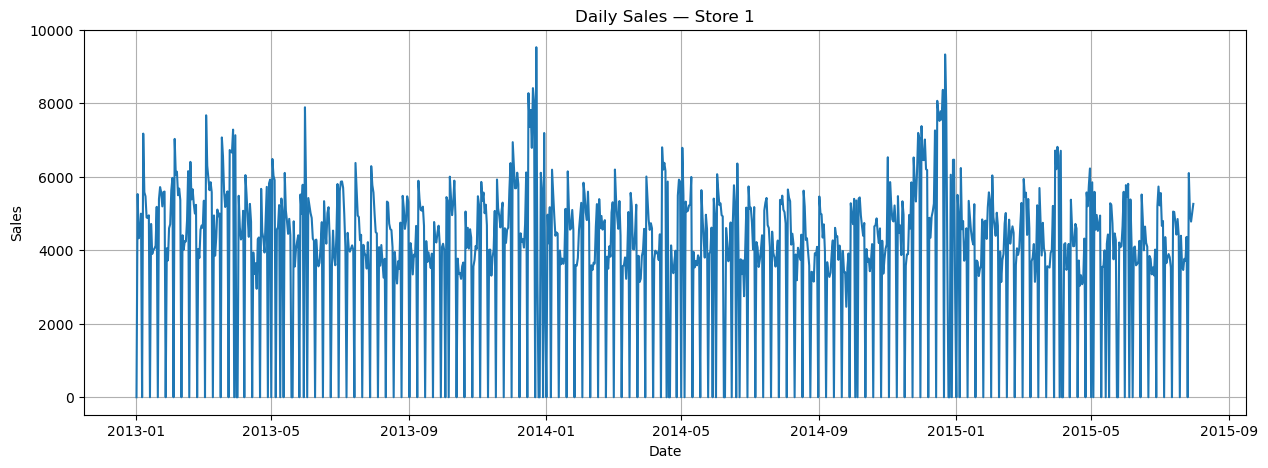

In [43]:
plt.figure(figsize=(15, 5))
plt.plot(store_series.index, store_series["Sales"])
plt.title("Daily Sales — Store 1")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

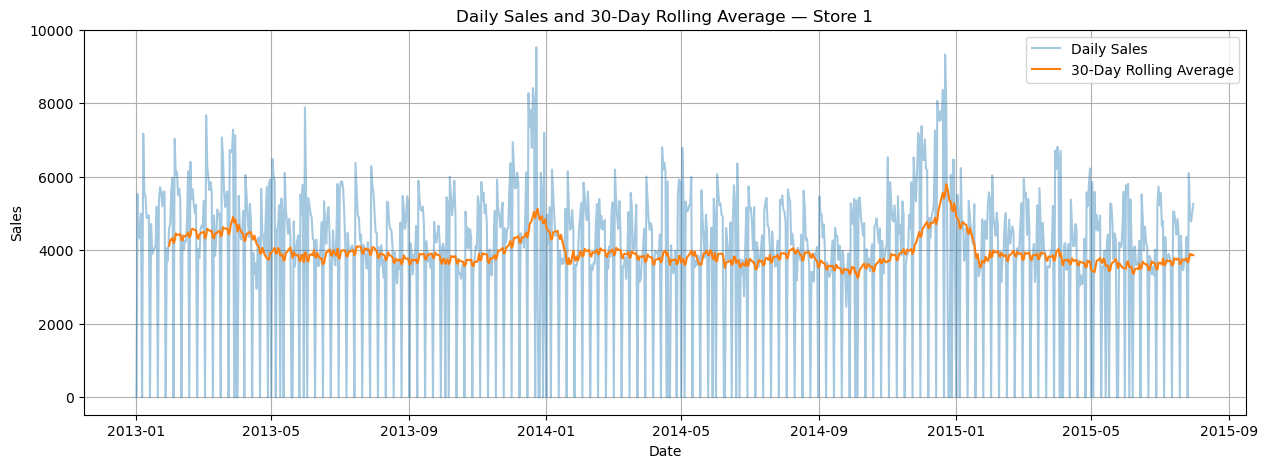

In [44]:
store_series["RollingMean30"] = (
    store_series["Sales"].rolling(window=30).mean()
)

plt.figure(figsize=(15, 5))
plt.plot(
    store_series.index,
    store_series["Sales"],
    label="Daily Sales",
    alpha=0.4
)
plt.plot(
    store_series.index,
    store_series["RollingMean30"],
    label="30-Day Rolling Average"
)
plt.title("Daily Sales and 30-Day Rolling Average — Store 1")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [45]:
sales_values = store_series["Sales"]

adf_result = adfuller(sales_values)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

if adf_result[1] <= 0.05:
    print("\nResult: Reject the null hypothesis. The series is likely stationary.")
else:
    print("\nResult: Fail to reject the null hypothesis. The series may be non-stationary.")

ADF Statistic: -4.368104368168515
p-value: 0.00033788346141422115
Critical Values:
1%: -3.4374778690219956
5%: -2.864686684217556
10%: -2.5684454926748583

Result: Reject the null hypothesis. The series is likely stationary.


DayOfWeek
1    4946.119403
2    4650.918519
3    4454.474074
4    4094.607407
5    4516.414815
6    4942.970149
7       0.000000
Name: Sales, dtype: float64

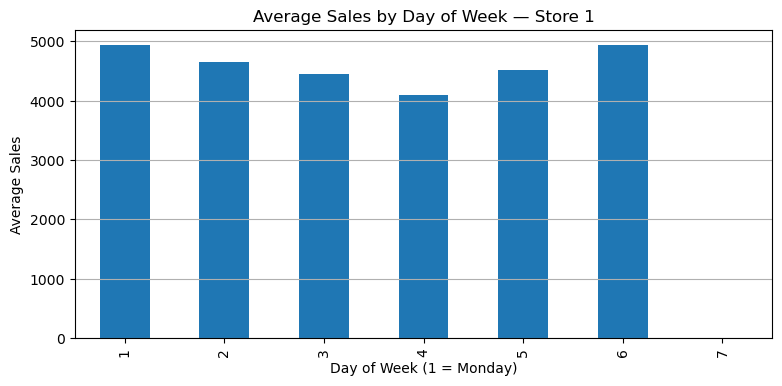

In [46]:
store_series["DayOfWeek"] = store_series.index.dayofweek + 1

weekday_sales = (
    store_series.groupby("DayOfWeek")["Sales"]
    .mean()
)

display(weekday_sales)

weekday_sales.plot(
    kind="bar",
    figsize=(9, 4),
    title="Average Sales by Day of Week — Store 1"
)

plt.xlabel("Day of Week (1 = Monday)")
plt.ylabel("Average Sales")
plt.grid(axis="y")
plt.show()

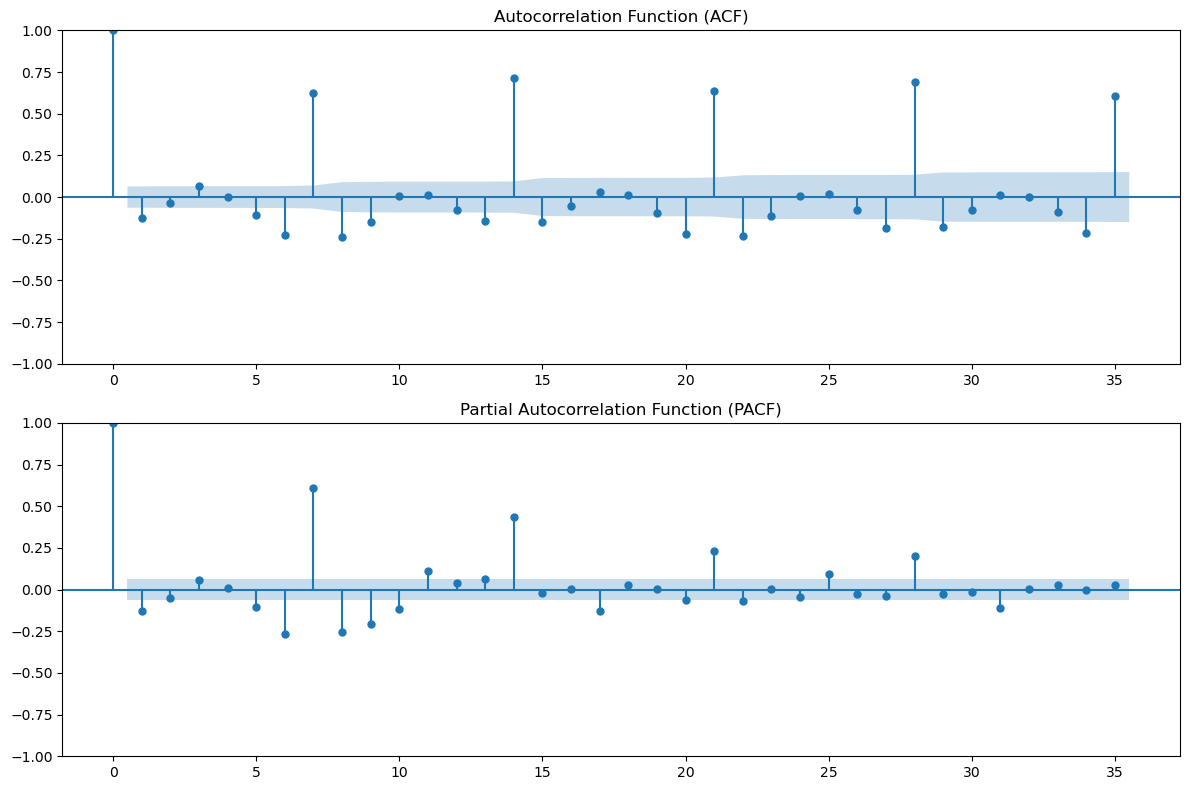

In [47]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    sales_values,
    lags=35,
    ax=axes[0]
)
axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(
    sales_values,
    lags=35,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

In [48]:
# Extract sales values
sales_data = store_series["Sales"].values.reshape(-1, 1)

# Initialize scaler
scaler = MinMaxScaler(feature_range=(-1, 1))

# Scale sales
scaled_sales = scaler.fit_transform(sales_data)

print("Original minimum:", sales_data.min())
print("Original maximum:", sales_data.max())

print("Scaled minimum:", scaled_sales.min())
print("Scaled maximum:", scaled_sales.max())

Original minimum: 0
Original maximum: 9528
Scaled minimum: -1.0
Scaled maximum: 1.0


In [49]:
def create_sequences(data, window_size=42):

    X = []
    y = []

    for i in range(len(data) - window_size):

        X.append(data[i:i + window_size])
        y.append(data[i + window_size])

    return np.array(X), np.array(y)


X, y = create_sequences(scaled_sales, window_size=42)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (900, 42, 1)
y shape: (900, 1)


In [50]:
split_index = int(len(X) * 0.8)

X_train_lstm = X[:split_index]
X_valid_lstm = X[split_index:]

y_train_lstm = y[:split_index]
y_valid_lstm = y[split_index:]

print("Training X:", X_train_lstm.shape)
print("Validation X:", X_valid_lstm.shape)

print("Training y:", y_train_lstm.shape)
print("Validation y:", y_valid_lstm.shape)

Training X: (720, 42, 1)
Validation X: (180, 42, 1)
Training y: (720, 1)
Validation y: (180, 1)


In [51]:
sales_data = store_series["Sales"].values.reshape(-1, 1)

# Chronological split: first 80% for training
split_point = int(len(sales_data) * 0.8)

train_raw = sales_data[:split_point]
valid_raw = sales_data[split_point:]

# Fit scaler only on training data
scaler = MinMaxScaler(feature_range=(-1, 1))

train_scaled = scaler.fit_transform(train_raw)

# Transform validation using the same scaler
valid_scaled = scaler.transform(valid_raw)

# Include the final 42 training days as context for validation
window_size = 42

valid_with_context = np.concatenate([
    train_scaled[-window_size:],
    valid_scaled
])

print("Training data:", train_scaled.shape)
print("Validation data:", valid_scaled.shape)
print("Validation with context:", valid_with_context.shape)

Training data: (753, 1)
Validation data: (189, 1)
Validation with context: (231, 1)


In [52]:
def create_sequences(data, window_size=42):

    X, y = [], []

    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])

    return np.array(X), np.array(y)


X_train_lstm, y_train_lstm = create_sequences(
    train_scaled,
    window_size
)

X_valid_lstm, y_valid_lstm = create_sequences(
    valid_with_context,
    window_size
)

print("Training X:", X_train_lstm.shape)
print("Training y:", y_train_lstm.shape)

print("Validation X:", X_valid_lstm.shape)
print("Validation y:", y_valid_lstm.shape)

Training X: (711, 42, 1)
Training y: (711, 1)
Validation X: (189, 42, 1)
Validation y: (189, 1)


In [53]:
tf.random.set_seed(42)

lstm_model = Sequential([
    tf.keras.Input(shape=(window_size, 1)),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 42, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 42, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:


early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    validation_data=(X_valid_lstm, y_valid_lstm),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.1871 - mae: 0.3137 - val_loss: 0.1548 - val_mae: 0.2895
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1835 - mae: 0.3184 - val_loss: 0.1541 - val_mae: 0.2859
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1833 - mae: 0.3168 - val_loss: 0.1531 - val_mae: 0.2873
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1827 - mae: 0.3165 - val_loss: 0.1523 - val_mae: 0.2865
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1816 - mae: 0.3155 - val_loss: 0.1516 - val_mae: 0.2872
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1818 - mae: 0.3159 - val_loss: 0.1517 - val_mae: 0.2827
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1815 - mae: 0.3143 - val_loss: 0.1514 - val_mae: 0.2858
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1807 - mae: 0.3129 - val_loss: 0.1510 - val_mae: 0.2822
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.179

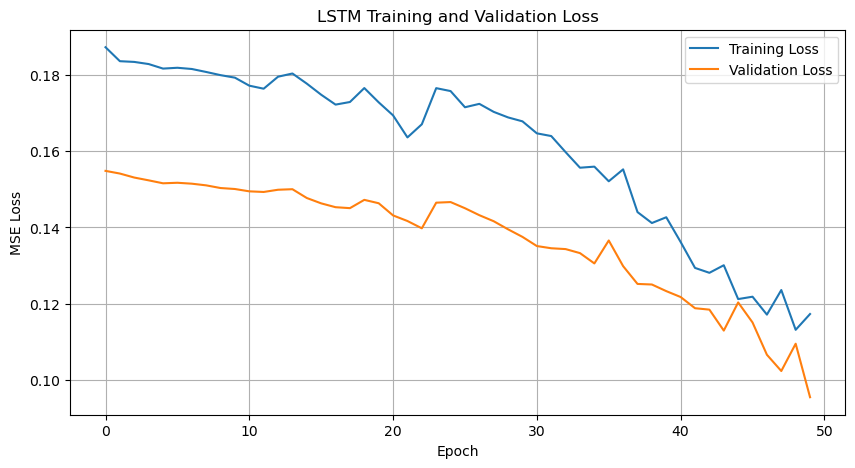

In [55]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

In [56]:
# Generate scaled predictions
predictions_scaled = lstm_model.predict(X_valid_lstm)

# Convert predictions back to original sales values
predictions_actual = scaler.inverse_transform(predictions_scaled)

# Convert validation targets back to original sales values
actual_sales = scaler.inverse_transform(y_valid_lstm)

# Calculate evaluation metrics
lstm_mae = mean_absolute_error(
    actual_sales,
    predictions_actual
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        actual_sales,
        predictions_actual
    )
)

print(f"LSTM MAE:  {lstm_mae:.2f}")
print(f"LSTM RMSE: {lstm_rmse:.2f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
LSTM MAE:  1088.42
LSTM RMSE: 1472.95


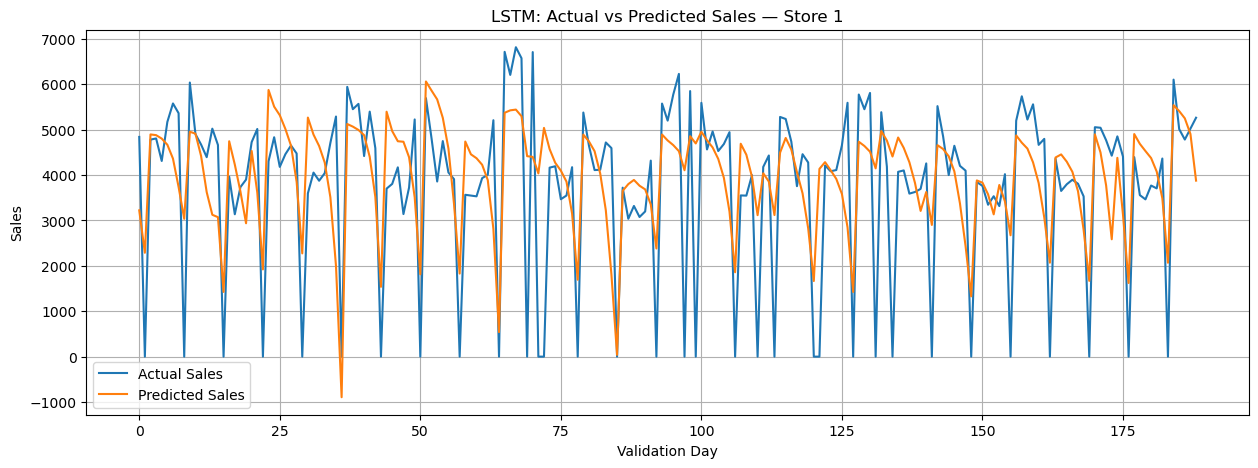

In [57]:
plt.figure(figsize=(15, 5))

plt.plot(
    actual_sales,
    label="Actual Sales"
)

plt.plot(
    predictions_actual,
    label="Predicted Sales"
)

plt.title("LSTM: Actual vs Predicted Sales — Store 1")
plt.xlabel("Validation Day")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [58]:
# Actual sales from 7 days before each validation target
seasonal_naive = sales_data[
    split_point - 7 : -7
]

naive_mae = mean_absolute_error(
    actual_sales,
    seasonal_naive
)

naive_rmse = np.sqrt(
    mean_squared_error(
        actual_sales,
        seasonal_naive
    )
)

print(f"7-day Seasonal Naive MAE:  {naive_mae:.2f}")
print(f"7-day Seasonal Naive RMSE: {naive_rmse:.2f}")

print(f"LSTM MAE:  {lstm_mae:.2f}")
print(f"LSTM RMSE: {lstm_rmse:.2f}")

7-day Seasonal Naive MAE:  1198.10
7-day Seasonal Naive RMSE: 1685.43
LSTM MAE:  1088.42
LSTM RMSE: 1472.95


In [59]:
# Use Store 1's original daily sales
sales_data = store_series["Sales"].values.reshape(-1, 1)

window_size = 42
forecast_horizon = 42

# Reserve the final 42 days for testing
train_raw = sales_data[:-forecast_horizon]
test_raw = sales_data[-forecast_horizon:]

# Fit scaler only on training data
scaler_6week = MinMaxScaler(feature_range=(-1, 1))

train_scaled = scaler_6week.fit_transform(train_raw)

# Create training sequences
X_6week, y_6week = create_sequences(
    train_scaled,
    window_size
)

print("Training sequences:", X_6week.shape)
print("Training targets:", y_6week.shape)
print("Forecast horizon:", forecast_horizon, "days")

Training sequences: (858, 42, 1)
Training targets: (858, 1)
Forecast horizon: 42 days


In [60]:
tf.random.set_seed(42)

lstm_6week = Sequential([
    tf.keras.Input(shape=(window_size, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

lstm_6week.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history_6week = lstm_6week.fit(
    X_6week,
    y_6week,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.1833 - mae: 0.3104 - val_loss: 0.1907 - val_mae: 0.3212
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1799 - mae: 0.3122 - val_loss: 0.1868 - val_mae: 0.3246
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1800 - mae: 0.3140 - val_loss: 0.1850 - val_mae: 0.3271
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1789 - mae: 0.3130 - val_loss: 0.1844 - val_mae: 0.3276
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1795 - mae: 0.3149 - val_loss: 0.1834 - val_mae: 0.3249
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.1773 - mae: 0.3133 - val_loss: 0.1830 - val_mae: 0.3219
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1782 - mae: 0.3137 - val_loss: 0.1821 - val_mae: 0.3188
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1774 - mae: 0.3134 - val_loss: 0.1825 - val_mae: 0.3179
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.175

In [61]:
# Start with the last 42 known training observations
current_window = train_scaled[-window_size:].copy()

recursive_predictions = []

for day in range(forecast_horizon):

    # Predict the next day
    next_prediction = lstm_6week.predict(
        current_window.reshape(1, window_size, 1),
        verbose=0
    )

    recursive_predictions.append(next_prediction[0, 0])

    # Append prediction and remove oldest observation
    current_window = np.concatenate([
        current_window[1:],
        next_prediction
    ])

# Convert predictions back to sales units
recursive_predictions = np.array(
    recursive_predictions
).reshape(-1, 1)

predictions_6week = scaler_6week.inverse_transform(
    recursive_predictions
)

actual_6week = test_raw

In [62]:
lstm_6week_mae = mean_absolute_error(
    actual_6week,
    predictions_6week
)

lstm_6week_rmse = np.sqrt(
    mean_squared_error(
        actual_6week,
        predictions_6week
    )
)

# Seasonal naive benchmark: same weekday, previous week
naive_6week = sales_data[
    len(sales_data) - forecast_horizon - 7:
    len(sales_data) - 7
]

naive_6week_mae = mean_absolute_error(
    actual_6week,
    naive_6week
)

naive_6week_rmse = np.sqrt(
    mean_squared_error(
        actual_6week,
        naive_6week
    )
)

print(f"LSTM 42-day MAE: {lstm_6week_mae:.2f}")
print(f"LSTM 42-day RMSE: {lstm_6week_rmse:.2f}")

print(f"Naive 42-day MAE: {naive_6week_mae:.2f}")
print(f"Naive 42-day RMSE: {naive_6week_rmse:.2f}")

LSTM 42-day MAE: 1901.38
LSTM 42-day RMSE: 2077.80
Naive 42-day MAE: 981.45
Naive 42-day RMSE: 1162.32


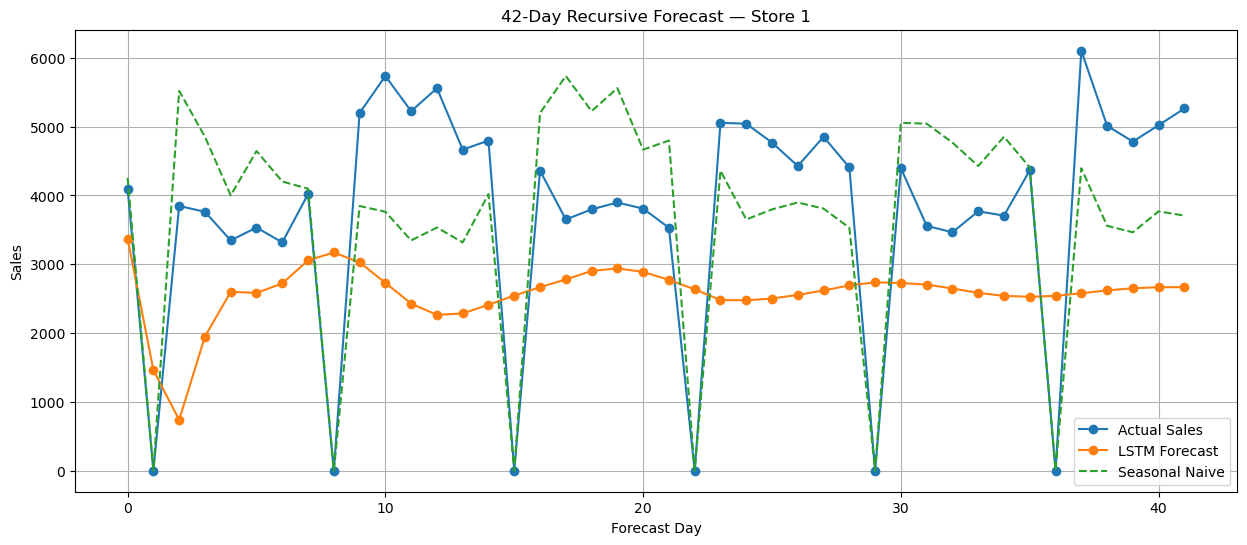

In [63]:
plt.figure(figsize=(15, 6))

plt.plot(
    actual_6week,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    predictions_6week,
    label="LSTM Forecast",
    marker="o"
)

plt.plot(
    naive_6week,
    label="Seasonal Naive",
    linestyle="--"
)

plt.title("42-Day Recursive Forecast — Store 1")
plt.xlabel("Forecast Day")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [64]:
# Generate 42-day recursive forecast
forecast_horizon = 42
window_size = 42

current_window = train_scaled[-window_size:].reshape(1, window_size, 1)

lstm_predictions_scaled = []

for _ in range(forecast_horizon):
    next_prediction = lstm_model.predict(current_window, verbose=0)

    lstm_predictions_scaled.append(next_prediction[0, 0])

    # Append prediction and remove oldest value
    current_window = np.append(
        current_window[:, 1:, :],
        next_prediction.reshape(1, 1, 1),
        axis=1
    )

# Convert predictions back to original sales scale
lstm_predictions = scaler.inverse_transform(
    np.array(lstm_predictions_scaled).reshape(-1, 1)
).flatten()

# Prevent negative predicted sales
lstm_predictions_clipped = np.maximum(lstm_predictions, 0)

In [65]:
# Repeat the last 7 observed training days for the entire forecast horizon
naive_6week = np.resize(train_raw[-7:], forecast_horizon)

# Ensure predictions cannot be negative
lstm_predictions_clipped = np.maximum(lstm_predictions, 0)

# Evaluate both models
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

lstm_mae = mean_absolute_error(test_raw, lstm_predictions_clipped)
lstm_rmse = np.sqrt(mean_squared_error(test_raw, lstm_predictions_clipped))

naive_mae = mean_absolute_error(test_raw, naive_6week)
naive_rmse = np.sqrt(mean_squared_error(test_raw, naive_6week))

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)

print("Seasonal Naive MAE:", naive_mae)
print("Seasonal Naive RMSE:", naive_rmse)

LSTM MAE: 1339.703857421875
LSTM RMSE: 1660.5185936929463
Seasonal Naive MAE: 581.3809523809524
Seasonal Naive RMSE: 725.8351511649644


In [66]:
# Prepare the multistore time-series dataset

lstm_panel = model_train[
    [
        "Store", "Date", "Sales", "Open",
        "Promo", "DayOfWeek", "StateHoliday",
        "SchoolHoliday", "StoreType", "Assortment",
        "CompetitionDistance", "Promo2"
    ]
].copy()

lstm_panel = lstm_panel.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

# Check duplicate store-date combinations
duplicate_count = lstm_panel.duplicated(
    subset=["Store", "Date"]
).sum()

# Check date gaps within each store
lstm_panel["DateGap"] = (
    lstm_panel.groupby("Store")["Date"].diff().dt.days
)

gap_counts = lstm_panel["DateGap"].value_counts().sort_index()

# Store-level date coverage
store_coverage = lstm_panel.groupby("Store").agg(
    FirstDate=("Date", "min"),
    LastDate=("Date", "max"),
    Records=("Date", "count")
)

print("Dataset shape:", lstm_panel.shape)
print("Number of stores:", lstm_panel["Store"].nunique())
print("Duplicate store-date records:", duplicate_count)

print("\nDate gap distribution:")
print(gap_counts.head(10))

print("\nStore coverage:")
print(store_coverage.describe())

print("\nStores with fewer than 900 records:")
print((store_coverage["Records"] < 900).sum())

Dataset shape: (1017209, 13)
Number of stores: 1115
Duplicate store-date records: 0

Date gap distribution:
DateGap
1.0      1015914
185.0        180
Name: count, dtype: int64

Store coverage:
                           FirstDate             LastDate      Records
count                           1115                 1115  1115.000000
mean   2013-01-01 00:01:17.488789248  2015-07-31 00:00:00   912.295067
min              2013-01-01 00:00:00  2015-07-31 00:00:00   758.000000
25%              2013-01-01 00:00:00  2015-07-31 00:00:00   942.000000
50%              2013-01-01 00:00:00  2015-07-31 00:00:00   942.000000
75%              2013-01-01 00:00:00  2015-07-31 00:00:00   942.000000
max              2013-01-02 00:00:00  2015-07-31 00:00:00   942.000000
std                              NaN                  NaN    67.729422

Stores with fewer than 900 records:
180


In [67]:
# Identify the stores and dates associated with the 185-day gaps

gap_rows = lstm_panel.loc[
    lstm_panel["DateGap"] > 1,
    ["Store", "Date", "DateGap"]
].copy()

print("Number of affected stores:", gap_rows["Store"].nunique())

print("\nFirst 15 gap records:")
print(gap_rows.head(15))

print("\nGap date distribution:")
print(gap_rows["Date"].value_counts().head(10))

print("\nAffected store IDs:")
print(sorted(gap_rows["Store"].unique()))

print("\nRecord counts for affected stores:")
print(
    store_coverage.loc[gap_rows["Store"].unique(), "Records"]
    .value_counts()
)

Number of affected stores: 180

First 15 gap records:
       Store       Date  DateGap
11850     13 2015-01-01    185.0
18260     20 2015-01-01    185.0
19960     22 2015-01-01    185.0
29196     32 2015-01-01    185.0
32780     36 2015-01-01    185.0
37306     41 2015-01-01    185.0
41832     46 2015-01-01    185.0
46358     51 2015-01-01    185.0
47116     52 2015-01-01    185.0
52584     58 2015-01-01    185.0
65588     72 2015-01-01    185.0
69172     76 2015-01-01    185.0
73698     81 2015-01-01    185.0
81050     89 2015-01-01    185.0
90286     99 2015-01-01    185.0

Gap date distribution:
Date
2015-01-01    180
Name: count, dtype: int64

Affected store IDs:
[np.int64(13), np.int64(20), np.int64(22), np.int64(32), np.int64(36), np.int64(41), np.int64(46), np.int64(51), np.int64(52), np.int64(58), np.int64(72), np.int64(76), np.int64(81), np.int64(89), np.int64(99), np.int64(100), np.int64(108), np.int64(113), np.int64(115), np.int64(127), np.int64(129), np.int64(132), np.int64

In [68]:
# Assign a separate segment whenever a store has a date gap
lstm_panel["Segment"] = (
    lstm_panel.groupby("Store")["DateGap"]
    .transform(lambda x: (x > 1).cumsum())
)

# Summarize continuous segments
segment_summary = (
    lstm_panel.groupby(["Store", "Segment"])
    .agg(
        StartDate=("Date", "min"),
        EndDate=("Date", "max"),
        Records=("Date", "count")
    )
    .reset_index()
)

print("Total continuous segments:", len(segment_summary))
print("\nSegment length distribution:")
print(segment_summary["Records"].describe())

print("\nShortest segments:")
print(segment_summary.nsmallest(10, "Records"))

print("\nSegments shorter than 42 days:")
print((segment_summary["Records"] < 42).sum())


Total continuous segments: 1295

Segment length distribution:
count    1295.000000
mean      785.489575
std       267.259247
min       212.000000
25%       546.000000
50%       942.000000
75%       942.000000
max       942.000000
Name: Records, dtype: float64

Shortest segments:
    Store  Segment  StartDate    EndDate  Records
13     13        1 2015-01-01 2015-07-31      212
21     20        1 2015-01-01 2015-07-31      212
24     22        1 2015-01-01 2015-07-31      212
35     32        1 2015-01-01 2015-07-31      212
40     36        1 2015-01-01 2015-07-31      212
46     41        1 2015-01-01 2015-07-31      212
52     46        1 2015-01-01 2015-07-31      212
58     51        1 2015-01-01 2015-07-31      212
60     52        1 2015-01-01 2015-07-31      212
67     58        1 2015-01-01 2015-07-31      212

Segments shorter than 42 days:
0


In [69]:

# Create a modelling copy
lstm_data = lstm_panel.copy()

# Normalize StateHoliday values
lstm_data["StateHoliday"] = (
    lstm_data["StateHoliday"]
    .astype(str)
    .replace({"0.0": "0"})
)

# Add date features
lstm_data["Year"] = lstm_data["Date"].dt.year
lstm_data["Month"] = lstm_data["Date"].dt.month
lstm_data["Day"] = lstm_data["Date"].dt.day

# Encode categorical features
lstm_data = pd.get_dummies(
    lstm_data,
    columns=["StateHoliday", "StoreType", "Assortment"],
    dtype=int
)

# Select model features
feature_columns = [
    "Sales",
    "DayOfWeek",
    "Open",
    "Promo",
    "SchoolHoliday",
    "CompetitionDistance",
    "Promo2",
    "Year",
    "Month",
    "Day"
]

feature_columns += [
    col for col in lstm_data.columns
    if col.startswith(("StateHoliday_", "StoreType_", "Assortment_"))
]

print("Feature count:", len(feature_columns))
print("Feature columns:", feature_columns)

print("\nMissing values:")
print(lstm_data[feature_columns].isnull().sum())

Feature count: 21
Feature columns: ['Sales', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'Promo2', 'Year', 'Month', 'Day', 'StateHoliday_0', 'StateHoliday_a', 'StateHoliday_b', 'StateHoliday_c', 'StoreType_a', 'StoreType_b', 'StoreType_c', 'StoreType_d', 'Assortment_a', 'Assortment_b', 'Assortment_c']

Missing values:
Sales                     0
DayOfWeek                 0
Open                      0
Promo                     0
SchoolHoliday             0
CompetitionDistance    2642
Promo2                    0
Year                      0
Month                     0
Day                       0
StateHoliday_0            0
StateHoliday_a            0
StateHoliday_b            0
StateHoliday_c            0
StoreType_a               0
StoreType_b               0
StoreType_c               0
StoreType_d               0
Assortment_a              0
Assortment_b              0
Assortment_c              0
dtype: int64


In [70]:
# Add competition-distance missing indicator
lstm_data["CompetitionDistanceMissing"] = (
    lstm_data["CompetitionDistance"].isna().astype(int)
)

# Impute missing competition distances using training median
competition_median = lstm_data.loc[
    lstm_data["Date"] < "2015-06-01",
    "CompetitionDistance"
].median()

lstm_data["CompetitionDistance"] = (
    lstm_data["CompetitionDistance"].fillna(competition_median)
)

# Store ID will be used separately as a categorical input
lstm_data["Store"] = lstm_data["Store"].astype("int32")

# Add missing indicator to feature list
feature_columns.append("CompetitionDistanceMissing")

print("Final feature count:", len(feature_columns))
print("Missing values remaining:", lstm_data[feature_columns].isnull().sum().sum())
print("Unique stores:", lstm_data["Store"].nunique())
print("Competition distance median:", competition_median)

Final feature count: 22
Missing values remaining: 0
Unique stores: 1115
Competition distance median: 2330.0


In [71]:
# Temporal split
train_cutoff = pd.Timestamp("2015-06-01")

# Fit scaler only on training-period observations
train_mask = lstm_data["Date"] < train_cutoff

lstm_scaler = MinMaxScaler(feature_range=(-1, 1))

lstm_scaler.fit(
    lstm_data.loc[train_mask, feature_columns]
)

# Transform all observations using the training-fitted scaler
lstm_data[feature_columns] = lstm_scaler.transform(
    lstm_data[feature_columns]
)

# Convert store IDs into embedding indices (0 to 1114)
store_to_index = {
    store_id: index
    for index, store_id in enumerate(sorted(lstm_data["Store"].unique()))
}

lstm_data["StoreIndex"] = lstm_data["Store"].map(store_to_index)

# Future-known features: everything except Sales
future_feature_columns = [
    col for col in feature_columns if col != "Sales"
]

print("Training rows:", train_mask.sum())
print("Validation rows:", (~train_mask).sum())
print("Historical input features:", len(feature_columns))
print("Future input features:", len(future_feature_columns))
print("Store embedding input size:", len(store_to_index))
print("Scaled feature range:")
print(
    lstm_data[feature_columns].agg(["min", "max"]).round(3)
)


Training rows: 949194
Validation rows: 68015
Historical input features: 22
Future input features: 21
Store embedding input size: 1115
Scaled feature range:
     Sales  DayOfWeek  Open  Promo  SchoolHoliday  CompetitionDistance  \
min -1.000       -1.0  -1.0   -1.0           -1.0                 -1.0   
max  1.146        1.0   1.0    1.0            1.0                  1.0   

     Promo2  Year  Month  Day  ...  StateHoliday_b  StateHoliday_c  \
min    -1.0  -1.0   -1.0 -1.0  ...            -1.0            -1.0   
max     1.0   1.0    1.0  1.0  ...             1.0             1.0   

     StoreType_a  StoreType_b  StoreType_c  StoreType_d  Assortment_a  \
min         -1.0         -1.0         -1.0         -1.0          -1.0   
max          1.0          1.0          1.0          1.0           1.0   

     Assortment_b  Assortment_c  CompetitionDistanceMissing  
min          -1.0          -1.0                        -1.0  
max           1.0           1.0                         1.0  

[2 

In [72]:
WINDOW_SIZE = 42
BATCH_SIZE = 256

# Convert the selected columns into NumPy arrays segment by segment
def sequence_generator(mode):
    for (store_id, segment_id), group in lstm_data.groupby(
        ["Store", "Segment"], sort=False
    ):
        group = group.sort_values("Date")

        historical = group[feature_columns].to_numpy(
            dtype=np.float32
        )

        future = group[future_feature_columns].to_numpy(
            dtype=np.float32
        )

        sales = group["Sales"].to_numpy(dtype=np.float32)

        dates = group["Date"].to_numpy()
        store_index = np.int32(group["StoreIndex"].iloc[0])

        for i in range(WINDOW_SIZE, len(group)):

            is_training = dates[i] < np.datetime64("2015-06-01")

            if mode == "train" and not is_training:
                continue

            if mode == "validation" and is_training:
                continue

            history_window = historical[i-WINDOW_SIZE:i]
            future_features = future[i]

            yield (
                (
                    history_window,
                    future_features,
                    store_index
                ),
                np.float32(sales[i])
            )


# Define the dataset output shapes
output_signature = (
    (
        tf.TensorSpec(
            shape=(WINDOW_SIZE, len(feature_columns)),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(len(future_feature_columns),),
            dtype=tf.float32
        ),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    ),
    tf.TensorSpec(shape=(), dtype=tf.float32)
)

# Build datasets
train_dataset = tf.data.Dataset.from_generator(
    lambda: sequence_generator("train"),
    output_signature=output_signature
)

validation_dataset = tf.data.Dataset.from_generator(
    lambda: sequence_generator("validation"),
    output_signature=output_signature
)

# Shuffle training examples, batch, and prefetch
train_dataset = (
    train_dataset
    .shuffle(20000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

validation_dataset = (
    validation_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and validation datasets created.")


Training and validation datasets created.


In [73]:
for (history_batch, future_batch, store_batch), target_batch in train_dataset.take(1):

    print("Historical input:", history_batch.shape)
    print("Future features:", future_batch.shape)
    print("Store input:", store_batch.shape)
    print("Sales target:", target_batch.shape)

Historical input: (256, 42, 22)
Future features: (256, 21)
Store input: (256,)
Sales target: (256,)


In [74]:
# Historical sequence: 42 days × 22 features
history_input = Input(
    shape=(WINDOW_SIZE, len(feature_columns)),
    name="history_input"
)

# Features known for the prediction date
future_input = Input(
    shape=(len(future_feature_columns),),
    name="future_input"
)

# Store identity
store_input = Input(
    shape=(),
    dtype="int32",
    name="store_input"
)

# Historical sequence branch: two LSTM layers
x = layers.LSTM(64, return_sequences=True)(history_input)
x = layers.Dropout(0.2)(x)
x = layers.LSTM(32)(x)
x = layers.Dropout(0.2)(x)

# Future features branch
future_branch = layers.Dense(32, activation="relu")(future_input)

# Store embedding branch
store_branch = layers.Embedding(
    input_dim=len(store_to_index),
    output_dim=16
)(store_input)

store_branch = layers.Flatten()(store_branch)

# Combine all three branches
combined = layers.Concatenate()([
    x,
    future_branch,
    store_branch
])

combined = layers.Dense(64, activation="relu")(combined)
combined = layers.Dropout(0.2)(combined)

output = layers.Dense(1)(combined)

lstm_model = Model(
    inputs=[history_input, future_input, store_input],
    outputs=output
)

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

lstm_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history_input       │ (None, 42, 22)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_4 (LSTM)       │ (None, 42, 64)    │     22,272 │ history_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 42, 64)    │          0 │ lstm_4[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ store_input         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_5 (LSTM)       │ (None, 32)        │     12,416 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_input        │ (None, 21)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 16)        │     17,840 │ store_input[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 32)        │          0 │ lstm_5[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        704 │ future_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 16)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 80)        │          0 │ dropout_5[0][0],  │
│ (Concatenate)       │                   │            │ dense_2[0][0],    │
│                     │                   │            │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      5,184 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         65 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 58,481 (228.44 KB)

 Trainable params: 58,481 (228.44 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5
    )
]

history = lstm_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


c:\Users\Sidd\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


   3496/Unknown 255s 71ms/step - loss: 0.0093 - mae: 0.0673

c:\Users\Sidd\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3496/3496 ━━━━━━━━━━━━━━━━━━━━ 275s 77ms/step - loss: 0.0093 - mae: 0.0673 - val_loss: 0.0032 - val_mae: 0.0393 - learning_rate: 0.0010
Epoch 2/20


c:\Users\Sidd\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


... (40 outputs left out)

3496/3496 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 0.0015 - mae: 0.0277

c:\Users\Sidd\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3496/3496 ━━━━━━━━━━━━━━━━━━━━ 336s 95ms/step - loss: 0.0015 - mae: 0.0277 - val_loss: 0.0023 - val_mae: 0.0317 - learning_rate: 5.0000e-04


c:\Users\Sidd\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [ ]:
sales_idx = feature_columns.index("Sales")

y_true_scaled = []
y_pred_scaled = []
naive_scaled = []

for (history_batch, future_batch, store_batch), target_batch in validation_dataset:

    predictions = lstm_model(
        [history_batch, future_batch, store_batch],
        training=False
    ).numpy().ravel()

    y_pred_scaled.extend(predictions)
    y_true_scaled.extend(target_batch.numpy().ravel())

    # Sales from the same weekday, 7 days before the target
    naive_scaled.extend(
        history_batch[:, -7, sales_idx].numpy()
    )

y_true_scaled = np.array(y_true_scaled)
y_pred_scaled = np.array(y_pred_scaled)
naive_scaled = np.array(naive_scaled)

# Convert scaled Sales back to original units
sales_scale = lstm_scaler.scale_[sales_idx]
sales_min = lstm_scaler.min_[sales_idx]

y_true = (y_true_scaled - sales_min) / sales_scale
y_pred = (y_pred_scaled - sales_min) / sales_scale
naive_pred = (naive_scaled - sales_min) / sales_scale

y_pred = np.maximum(y_pred, 0)
naive_pred = np.maximum(naive_pred, 0)

print("LSTM MAE:", mean_absolute_error(y_true, y_pred))
print("LSTM RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))

print("Seasonal Naive MAE:", mean_absolute_error(y_true, naive_pred))
print("Seasonal Naive RMSE:", np.sqrt(mean_squared_error(y_true, naive_pred)))


In [ ]:
print("Completed epochs:", len(history.history["loss"]))

print("Final training MAE:", history.history["mae"][-1])
print("Final validation MAE:", history.history["val_mae"][-1])

Completed epochs: 19
Final training MAE: 0.026977969333529472
Final validation MAE: 0.029766829684376717


In [ ]:
print("Completed epochs:", len(history.history["loss"]))
print("Best validation MAE:", min(history.history["val_mae"]))
print("Best validation loss:", min(history.history["val_loss"]))

Completed epochs: 19
Best validation MAE: 0.02867092937231064
Best validation loss: 0.001897044014185667


In [ ]:
os.makedirs("models", exist_ok=True)

lstm_model.save("models/global_lstm.keras")
joblib.dump(lstm_scaler, "models/lstm_scaler.pkl")
joblib.dump(store_to_index, "models/store_to_index.pkl")

print("LSTM model and preprocessing objects saved.")

LSTM model and preprocessing objects saved.


In [ ]:
FORECAST_START = pd.Timestamp("2015-06-01")
FORECAST_DAYS = 42

forecast_dates = pd.date_range(
    start=FORECAST_START,
    periods=FORECAST_DAYS,
    freq="D"
)

sales_idx = feature_columns.index("Sales")
store_groups = {
    store_id: group.sort_values("Date").set_index("Date")
    for store_id, group in lstm_data.groupby("Store")
}

# Initialize the last 42 days of history for every store
store_histories = {}

for store_id, group in store_groups.items():
    past = group.loc[group.index < FORECAST_START].tail(WINDOW_SIZE)

    if len(past) == WINDOW_SIZE:
        store_histories[store_id] = past[feature_columns].to_numpy(
            dtype=np.float32
        )

print("Stores ready:", len(store_histories))

Stores ready: 1115


In [ ]:
all_predictions = []
all_actuals = []

for forecast_date in forecast_dates:

    history_batch = []
    future_batch = []
    store_batch = []
    active_stores = []

    for store_id, history_array in store_histories.items():

        group = store_groups[store_id]

        if forecast_date not in group.index:
            continue

        future_row = group.loc[forecast_date]

        history_batch.append(history_array)
        future_batch.append(
            future_row[future_feature_columns].to_numpy(dtype=np.float32)
        )
        store_batch.append(store_to_index[store_id])
        active_stores.append(store_id)

    if not active_stores:
        continue

    predictions_scaled = lstm_model.predict(
        [
            np.asarray(history_batch),
            np.asarray(future_batch, dtype=np.float32),
            np.asarray(store_batch, dtype=np.int32)
        ],
        verbose=0
    ).ravel()

    for i, store_id in enumerate(active_stores):

        group = store_groups[store_id]
        actual_scaled = group.loc[forecast_date, "Sales"]

        # Convert predictions to original sales units
        predicted_sales = (
            predictions_scaled[i] - lstm_scaler.min_[sales_idx]
        ) / lstm_scaler.scale_[sales_idx]

        actual_sales = (
            actual_scaled - lstm_scaler.min_[sales_idx]
        ) / lstm_scaler.scale_[sales_idx]

        predicted_sales = max(0, predicted_sales)

        all_predictions.append(predicted_sales)
        all_actuals.append(actual_sales)

        # Append predicted day to history, not actual Sales
        new_row = group.loc[forecast_date, feature_columns].to_numpy(
            dtype=np.float32
        ).copy()

        new_row[sales_idx] = predictions_scaled[i]

        store_histories[store_id] = np.vstack([
            store_histories[store_id][1:],
            new_row
        ])

print("Forecast observations:", len(all_predictions))

Forecast observations: 46830


In [ ]:
fixed_origin_mae = mean_absolute_error(
    all_actuals, all_predictions
)

fixed_origin_rmse = np.sqrt(
    mean_squared_error(all_actuals, all_predictions)
)

print("42-Day Fixed-Origin LSTM MAE:", fixed_origin_mae)
print("42-Day Fixed-Origin LSTM RMSE:", fixed_origin_rmse)

42-Day Fixed-Origin LSTM MAE: 630.0595180699294
42-Day Fixed-Origin LSTM RMSE: 976.3745144300948


In [ ]:
naive_actuals_scaled = []
naive_predictions_scaled = []

for store_id, group in store_groups.items():
    past_sales = group.loc[
        group.index < FORECAST_START, "Sales"
    ].tail(7).to_numpy()

    future_actuals = group.loc[
        forecast_dates, "Sales"
    ].to_numpy()

    if len(past_sales) != 7 or len(future_actuals) != 42:
        continue

    naive_predictions_scaled.extend(
        np.resize(past_sales, FORECAST_DAYS)
    )
    naive_actuals_scaled.extend(future_actuals)

naive_actuals = (
    np.array(naive_actuals_scaled) - lstm_scaler.min_[sales_idx]
) / lstm_scaler.scale_[sales_idx]

naive_predictions = (
    np.array(naive_predictions_scaled) - lstm_scaler.min_[sales_idx]
) / lstm_scaler.scale_[sales_idx]

print("42-Day Seasonal Naive MAE:",
      mean_absolute_error(naive_actuals, naive_predictions))

print("42-Day Seasonal Naive RMSE:",
      np.sqrt(mean_squared_error(naive_actuals, naive_predictions)))

42-Day Seasonal Naive MAE: 2181.3957719410632
42-Day Seasonal Naive RMSE: 3816.717474702544


In [ ]:
results = pd.DataFrame({
    "Model": ["Global LSTM", "Seasonal Naive"],
    "MAE": [630.0595, 2181.3958],
    "RMSE": [976.3745, 3816.7175]
})

results

,Model,MAE,RMSE
0,Global LSTM,630.0595,976.3745
1,Seasonal Naive,2181.3958,3816.7175


In [ ]:

os.makedirs("models", exist_ok=True)

best_et_model = et_models["et_100_leaf5_features08"]

joblib.dump(best_et_model, "models/best_extratrees_pipeline.pkl")

print("ExtraTrees pipeline saved.")

KeyError: 'et_100_leaf5_features08'

In [ ]:
# Find variables in the notebook that may contain trained ExtraTrees models
candidates = [
    name for name in globals()
    if any(term in name.lower() for term in ["extra", "et_model", "model"])
]

print("Potential model variables:")
for name in candidates:
    obj = globals()[name]
    print(f"{name}: {type(obj).__name__}")

# If et_models exists, inspect its actual keys
if "et_models" in globals():
    print("\net_models keys:")
    print(list(et_models.keys()))

Potential model variables:
ExtraTreesRegressor: ABCMeta
model_train: DataFrame
model_test: DataFrame
model_data: DataFrame
baseline_model: Pipeline
lag_model_data: DataFrame
lag_model: Pipeline
models: dict
model_name: str
model_pipeline: Pipeline
model_comparison: DataFrame
et_models: dict
lstm_model: Functional
Model: type

et_models keys:
['Extra Trees - Baseline', 'Extra Trees - More Trees', 'Extra Trees - Larger Leaves', 'Extra Trees - Feature Sampling']


In [ ]:
for key, value in et_models.items():
    print(key, type(value).__name__)

Extra Trees - Baseline Pipeline
Extra Trees - More Trees Pipeline
Extra Trees - Larger Leaves Pipeline
Extra Trees - Feature Sampling Pipeline


In [ ]:
best_et_model = et_models["Extra Trees - Feature Sampling"]

print(best_et_model)
print("\nPipeline steps:", best_et_model.named_steps.keys())

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Store', 'DayOfWeek',
                                                   'Promo', 'SchoolHoliday',
                                                   'CompetitionDistance',
                                                   'CompetitionOpenSinceMonth',
                                                   'CompetitionOpenSinceYear',
                                                   'Promo2', 'Promo2SinceWeek',
                                                   'Promo2SinceYear', 'Year',
                                                   'Month', 'Day', 'WeekOfYear',
                                                   'IsWeekend', 'IsMonthStart',
                      

In [ ]:
os.makedirs("models", exist_ok=True)

joblib.dump(
    best_et_model,
    "models/best_extratrees_pipeline.pkl"
)

print("Best ExtraTrees pipeline saved successfully.")

Best ExtraTrees pipeline saved successfully.


In [ ]:
et_valid_predictions = np.maximum(best_et_model.predict(X_valid), 0)

et_mae = mean_absolute_error(y_valid, et_valid_predictions)
et_rmse = np.sqrt(mean_squared_error(y_valid, et_valid_predictions))

print(f"Extra Trees Validation MAE:  {et_mae:.2f}")
print(f"Extra Trees Validation RMSE: {et_rmse:.2f}")

Extra Trees Validation MAE:  705.14
Extra Trees Validation RMSE: 1021.69


In [ ]:
try:
    import mlflow
    print("MLflow version:", mlflow.__version__)
except ImportError:
    print("MLflow is not installed.")

MLflow version: 3.16.1


In [ ]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Rossmann_Sales_Forecasting")

print("Tracking URI:", mlflow.get_tracking_uri())
print(
    "Experiment:",
    mlflow.get_experiment_by_name("Rossmann_Sales_Forecasting").name
)

2026/11/04 15:25:54 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/04 15:25:54 INFO mlflow.store.db.utils: Updating database tables
2026/11/04 15:25:56 INFO mlflow.tracking.fluent: Experiment with name 'Rossmann_Sales_Forecasting' does not exist. Creating a new experiment.


Tracking URI: sqlite:///mlflow.db
Experiment: Rossmann_Sales_Forecasting


In [ ]:
os.makedirs("models", exist_ok=True)

lstm_model.save("models/global_lstm.keras")
joblib.dump(lstm_scaler, "models/lstm_scaler.pkl")

lstm_preprocessing = {
    "feature_columns": feature_columns,
    "future_feature_columns": future_feature_columns,
    "store_to_index": store_to_index,
    "competition_median": competition_median
}

joblib.dump(
    lstm_preprocessing,
    "models/lstm_preprocessing.pkl"
)

print("LSTM model and preprocessing files saved.")

LSTM model and preprocessing files saved.


In [ ]:
with mlflow.start_run(run_name="Global_LSTM"):

    mlflow.log_params({
        "model": "Global LSTM",
        "architecture": "LSTM(64) -> LSTM(32) -> Dense",
        "sequence_length": 42,
        "dropout": 0.2,
        "optimizer": "Adam",
        "loss": "MSE",
        "forecast_horizon": 42,
        "number_of_stores": 1115
    })

    mlflow.log_metrics({
        "fixed_origin_mae": 630.06,
        "fixed_origin_rmse": 976.37
    })

    mlflow.tensorflow.log_model(
        model=lstm_model,
        name="global_lstm_model"
    )

    mlflow.log_artifacts("models", artifact_path="preprocessing")

    print("Global LSTM logged successfully!")
    print("Run ID:", mlflow.active_run().info.run_id)

2026/11/04 15:26:29 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


Global LSTM logged successfully!
Run ID: 5c3b75c0bf9f44d69b3bcfea471ddbb3


In [ ]:
os.makedirs("models", exist_ok=True)

# Save the store metadata needed to construct prediction inputs
joblib.dump(store_info, "models/store_info.pkl")

# Save the model and its expected input columns together
app_bundle = {
    "model": best_et_model,
    "features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features
}

joblib.dump(app_bundle, "models/sales_app_bundle.pkl")

print("App dependencies saved.")
print("Stores available:", len(store_info))
print("Expected model inputs:", len(features))

App dependencies saved.
Stores available: 1115
Expected model inputs: 21


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
from datetime import date

# Load saved model and store metadata
bundle = joblib.load("models/sales_app_bundle.pkl")
store_info = joblib.load("models/store_info.pkl")

model = bundle["model"]
features = bundle["features"]

st.set_page_config(
    page_title="Rossmann Sales Forecast",
    page_icon="📊",
    layout="wide"
)

st.title("Rossmann Store Sales Forecast")
st.write("Predict daily sales using store information, dates, promotions and holidays.")

# Sidebar inputs
st.sidebar.header("Forecast Configuration")

store_ids = sorted(store_info["Store"].unique())

selected_store = st.sidebar.selectbox(
    "Select Store",
    store_ids
)

start_date = st.sidebar.date_input(
    "Start Date",
    value=date(2015, 8, 1)
)

end_date = st.sidebar.date_input(
    "End Date",
    value=date(2015, 8, 7)
)

promo = st.sidebar.selectbox("Promotion Active?", [0, 1])
school_holiday = st.sidebar.selectbox("School Holiday?", [0, 1])

state_holiday = st.sidebar.selectbox(
    "State Holiday",
    ["0", "a", "b", "c"],
    format_func=lambda x: {
        "0": "None",
        "a": "Public Holiday",
        "b": "Easter Holiday",
        "c": "Christmas"
    }[x]
)

# Validate date range
if start_date > end_date:
    st.error("Start date must be before or equal to end date.")
    st.stop()

if (end_date - start_date).days > 41:
    st.error("Please select a maximum forecast period of 42 days.")
    st.stop()

# Retrieve selected store metadata
store_row = store_info.loc[
    store_info["Store"] == selected_store
].iloc[0]

# Generate prediction input rows
dates = pd.date_range(start_date, end_date, freq="D")
prediction_rows = []

for current_date in dates:
    row = {
        "Store": selected_store,
        "DayOfWeek": current_date.dayofweek + 1,
        "Promo": promo,
        "SchoolHoliday": school_holiday,
        "CompetitionDistance": store_row["CompetitionDistance"],
        "CompetitionOpenSinceMonth": store_row["CompetitionOpenSinceMonth"],
        "CompetitionOpenSinceYear": store_row["CompetitionOpenSinceYear"],
        "Promo2": store_row["Promo2"],
        "Promo2SinceWeek": store_row["Promo2SinceWeek"],
        "Promo2SinceYear": store_row["Promo2SinceYear"],
        "Year": current_date.year,
        "Month": current_date.month,
        "Day": current_date.day,
        "WeekOfYear": int(current_date.isocalendar().week),
        "IsWeekend": int(current_date.dayofweek >= 5),
        "IsMonthStart": int(current_date.is_month_start),
        "IsMonthEnd": int(current_date.is_month_end),
        "StoreType": store_row["StoreType"],
        "Assortment": store_row["Assortment"],
        "StateHoliday": state_holiday,
        "PromoInterval": store_row["PromoInterval"]
    }

    prediction_rows.append(row)

input_data = pd.DataFrame(prediction_rows)[features]

# Prediction
if st.sidebar.button("Generate Forecast", type="primary"):
    predictions = np.maximum(model.predict(input_data), 0)

    results = pd.DataFrame({
        "Date": dates,
        "Predicted_Sales": predictions.round(2)
    })

    st.subheader(f"Forecast for Store {selected_store}")

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Total Predicted Sales",
        f"{results['Predicted_Sales'].sum():,.0f}"
    )

    col2.metric(
        "Average Daily Sales",
        f"{results['Predicted_Sales'].mean():,.0f}"
    )

    col3.metric(
        "Forecast Days",
        len(results)
    )

    st.subheader("Daily Sales Forecast")
    st.line_chart(
        results.set_index("Date")["Predicted_Sales"]
    )

    st.subheader("Prediction Details")
    st.dataframe(results, use_container_width=True)

    csv = results.to_csv(index=False).encode("utf-8")

    st.download_button(
        label="Download Forecast CSV",
        data=csv,
        file_name=f"store_{selected_store}_forecast.csv",
        mime="text/csv"
    )

st.caption(
    "Note: Promo and holiday selections are applied uniformly across the "
    "selected dates. Predictions are estimates from the trained Extra Trees model."
)

Overwriting app.py


In [ ]:
import os

required_files = [
    "models/best_extratrees_pipeline.pkl",
    "models/sales_app_bundle.pkl",
    "models/store_info.pkl",
    "models/global_lstm.keras",
    "models/lstm_scaler.pkl",
    "models/lstm_preprocessing.pkl",
    "mlflow.db",
    "app.py",
    "requirements.txt"
]

for file in required_files:
    status = "FOUND" if os.path.exists(file) else "MISSING"
    print(f"{status}: {file}")

MISSING: models/best_extratrees_pipeline.pkl
MISSING: models/sales_app_bundle.pkl
MISSING: models/store_info.pkl
MISSING: models/global_lstm.keras
MISSING: models/lstm_scaler.pkl
MISSING: models/lstm_preprocessing.pkl
MISSING: mlflow.db
MISSING: app.py
MISSING: requirements.txt


In [ ]:


os.chdir("..")

print("Project root:", os.getcwd())
print("Models folder exists:", os.path.exists("models"))

Project root: z:\Projec _ Internship\Proj_6
Models folder exists: True


In [ ]:


required_files = [
    "models/best_extratrees_pipeline.pkl",
    "models/sales_app_bundle.pkl",
    "models/store_info.pkl",
    "models/global_lstm.keras",
    "models/lstm_scaler.pkl",
    "models/lstm_preprocessing.pkl",
    "mlflow.db",
    "app.py",
    "requirements.txt"
]

for file in required_files:
    status = "FOUND" if os.path.exists(file) else "MISSING"
    print(f"{status}: {file}")

FOUND: models/best_extratrees_pipeline.pkl
FOUND: models/sales_app_bundle.pkl
FOUND: models/store_info.pkl
FOUND: models/global_lstm.keras
FOUND: models/lstm_scaler.pkl
FOUND: models/lstm_preprocessing.pkl
FOUND: mlflow.db
FOUND: app.py
FOUND: requirements.txt


In [ ]:
import pandas as pd
import numpy as np
import joblib


# Load saved artifacts
bundle = joblib.load("models/sales_app_bundle.pkl")
store_info = joblib.load("models/store_info.pkl")

best_model = bundle["model"]
features = bundle["features"]

# Load original test data
test_inference = pd.read_csv("data/test.csv")
test_inference["Date"] = pd.to_datetime(test_inference["Date"])

# Track and impute missing Open values
test_inference["Open_was_missing"] = test_inference["Open"].isna().astype(int)
test_inference["Open"] = test_inference["Open"].fillna(1)

# Normalize StateHoliday
test_inference["StateHoliday"] = (
    test_inference["StateHoliday"]
    .astype(str)
    .replace({"0.0": "0"})
)

# Merge store metadata
test_inference = test_inference.merge(
    store_info,
    on="Store",
    how="left",
    validate="many_to_one"
)

# Create the same date features used during training
test_inference["Year"] = test_inference["Date"].dt.year
test_inference["Month"] = test_inference["Date"].dt.month
test_inference["Day"] = test_inference["Date"].dt.day
test_inference["WeekOfYear"] = (
    test_inference["Date"].dt.isocalendar().week.astype(int)
)
test_inference["IsWeekend"] = (
    test_inference["DayOfWeek"].isin([6, 7]).astype(int)
)
test_inference["IsMonthStart"] = (
    test_inference["Date"].dt.is_month_start.astype(int)
)
test_inference["IsMonthEnd"] = (
    test_inference["Date"].dt.is_month_end.astype(int)
)

# Prepare model input in the exact training feature order
X_test = test_inference[features].copy()

# Predict sales
test_predictions = np.maximum(best_model.predict(X_test), 0)

# Closed stores receive zero sales
test_predictions[test_inference["Open"].to_numpy() == 0] = 0

# Create submission
submission = pd.DataFrame({
    "Id": test_inference["Id"],
    "Sales": test_predictions
})

os.makedirs("outputs", exist_ok=True)
submission.to_csv("outputs/rossmann_submission.csv", index=False)

print("Test rows:", len(submission))
print("Prediction rows:", len(test_predictions))
print("Missing predictions:", submission["Sales"].isna().sum())
print("Minimum predicted sales:", submission["Sales"].min())
print("Maximum predicted sales:", submission["Sales"].max())
print("\nSubmission preview:")
print(submission.head())

Test rows: 41088
Prediction rows: 41088
Missing predictions: 0
Minimum predicted sales: 0.0
Maximum predicted sales: 29660.294170738063

Submission preview:
   Id        Sales
0   1  4401.267203
1   2  7604.733919
2   3  9064.500085
3   4  7558.737025
4   5  7746.147874


In [ ]:
import pandas as pd
import numpy as np


# Load training data
train_customer = pd.read_csv("data/train.csv")
store_info = joblib.load("models/store_info.pkl")

train_customer["Date"] = pd.to_datetime(train_customer["Date"])

# Normalize StateHoliday
train_customer["StateHoliday"] = (
    train_customer["StateHoliday"]
    .astype(str)
    .replace({"0.0": "0"})
)

# Merge store metadata
model_train = train_customer.merge(
    store_info,
    on="Store",
    how="left",
    validate="many_to_one"
)

# Recreate date features
model_train["Year"] = model_train["Date"].dt.year
model_train["Month"] = model_train["Date"].dt.month
model_train["Day"] = model_train["Date"].dt.day
model_train["WeekOfYear"] = (
    model_train["Date"].dt.isocalendar().week.astype(int)
)
model_train["IsWeekend"] = (
    model_train["DayOfWeek"].isin([6, 7]).astype(int)
)
model_train["IsMonthStart"] = (
    model_train["Date"].dt.is_month_start.astype(int)
)
model_train["IsMonthEnd"] = (
    model_train["Date"].dt.is_month_end.astype(int)
)

# Recover exact feature order from saved app bundle
bundle = joblib.load("models/sales_app_bundle.pkl")
features = bundle["features"]
best_model = bundle["model"]

print("Training data:", model_train.shape)
print("Feature count:", len(features))
print("Customers available:", model_train["Customers"].notna().sum())

C:\Users\Sidd\AppData\Local\Temp\ipykernel_15036\1524694712.py:6: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train_customer = pd.read_csv("data/train.csv")


Training data: (1017209, 25)
Feature count: 21
Customers available: 1017209


In [ ]:
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np



# Include all open stores with available customer targets
customer_data = model_train[
    (model_train["Open"] == 1) &
    (model_train["Customers"].notna())
].copy()

# Same chronological validation split
customer_train = customer_data[
    customer_data["Date"] < "2015-06-01"
].copy()

customer_valid = customer_data[
    customer_data["Date"] >= "2015-06-01"
].copy()

X_customer_train = customer_train[features]
y_customer_train = customer_train["Customers"]

X_customer_valid = customer_valid[features]
y_customer_valid = customer_valid["Customers"]

# Reuse the sales model's preprocessing structure
customer_model = Pipeline([
    ("preprocessor", clone(best_model.named_steps["preprocessor"])),
    ("regressor", ExtraTreesRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
customer_model.fit(X_customer_train, y_customer_train)

# Validate
customer_predictions = np.maximum(
    customer_model.predict(X_customer_valid), 0
)

customer_mae = mean_absolute_error(
    y_customer_valid, customer_predictions
)

customer_rmse = np.sqrt(
    mean_squared_error(y_customer_valid, customer_predictions)
)

print("Customer training rows:", len(customer_train))
print("Customer validation rows:", len(customer_valid))
print(f"Customer MAE: {customer_mae:.2f}")
print(f"Customer RMSE: {customer_rmse:.2f}")

Customer training rows: 785781
Customer validation rows: 58611
Customer MAE: 55.56
Customer RMSE: 79.40


In [ ]:

print("Customer pipeline saved:",
      os.path.exists("models/customer_extratrees_pipeline.pkl"))

print("Customer app bundle saved:",
      os.path.exists("models/customer_app_bundle.pkl"))

Customer pipeline saved: True
Customer app bundle saved: True


In [ ]:
import mlflow
from mlflow.models import infer_signature

signature = infer_signature(
    X_customer_valid.head(5),
    customer_predictions[:5]
)

with mlflow.start_run(run_name="Extra_Trees_Customer_Model"):

    mlflow.log_params({
        "model": "ExtraTreesRegressor",
        "n_estimators": 100,
        "min_samples_leaf": 5,
        "max_features": 0.8,
        "random_state": 42
    })

    mlflow.log_metrics({
        "validation_mae": customer_mae,
        "validation_rmse": customer_rmse
    })

    mlflow.sklearn.log_model(
        sk_model=customer_model,
        name="customer_extratrees_model",
        signature=signature,
        input_example=X_customer_valid.head(5),
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
            "sklearn.tree._tree.Tree"
        ]
    )

print("Customer model logged successfully!")

c:\Users\Sidd\anaconda3\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/06 12:02:45 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/06 12:02:45 INFO mlflow.store.db.utils: Updating database tables


Customer model logged successfully!


In [ ]:
import os
import joblib
from datetime import datetime

# Create version directory
os.makedirs("models/versions", exist_ok=True)

# Load saved models
sales_bundle = joblib.load("models/sales_app_bundle.pkl")
customer_bundle = joblib.load("models/customer_app_bundle.pkl")

# Timestamp
timestamp = datetime.now().strftime("%d-%m-%Y-%H-%M-%S")

# Save timestamped versions
joblib.dump(
    sales_bundle,
    f"models/versions/sales_model_{timestamp}.pkl"
)

joblib.dump(
    customer_bundle,
    f"models/versions/customer_model_{timestamp}.pkl"
)

# Save LSTM model
import tensorflow as tf

lstm_model = tf.keras.models.load_model("models/global_lstm.keras")

lstm_model.save(
    f"models/versions/global_lstm_{timestamp}.keras"
)

print("All three model versions saved!")
print("Timestamp:", timestamp)
print("Files:", os.listdir("models/versions"))

All three model versions saved!
Timestamp: 06-11-2026-12-03-16
Files: ['customer_model_06-11-2026-10-22-59.pkl', 'customer_model_06-11-2026-12-03-16.pkl', 'global_lstm_06-11-2026-10-22-59.keras', 'global_lstm_06-11-2026-12-03-16.keras', 'sales_model_06-11-2026-10-22-59.pkl', 'sales_model_06-11-2026-12-03-16.pkl']


In [ ]:
import pandas as pd
import joblib
import numpy as np

# Load saved model bundle and store metadata
sales_bundle = joblib.load("models/sales_app_bundle.pkl")
store_info = joblib.load("models/store_info.pkl")

best_model = sales_bundle["model"]
features = sales_bundle["features"]

# Reload training data
train_conf = pd.read_csv("data/train.csv")
train_conf["Date"] = pd.to_datetime(train_conf["Date"])

# Normalize StateHoliday
train_conf["StateHoliday"] = (
    train_conf["StateHoliday"].astype(str).replace({"0.0": "0"})
)

# Merge store metadata
model_conf = train_conf.merge(
    store_info,
    on="Store",
    how="left",
    validate="many_to_one"
)

# Recreate date features
model_conf["Year"] = model_conf["Date"].dt.year
model_conf["Month"] = model_conf["Date"].dt.month
model_conf["Day"] = model_conf["Date"].dt.day
model_conf["WeekOfYear"] = model_conf["Date"].dt.isocalendar().week.astype(int)
model_conf["IsWeekend"] = model_conf["DayOfWeek"].isin([6, 7]).astype(int)
model_conf["IsMonthStart"] = model_conf["Date"].dt.is_month_start.astype(int)
model_conf["IsMonthEnd"] = model_conf["Date"].dt.is_month_end.astype(int)

# Recreate validation split
model_conf = model_conf[
    (model_conf["Open"] == 1) & (model_conf["Sales"] > 0)
].copy()

validation_start = pd.Timestamp("2015-06-01")

valid_conf = model_conf[
    model_conf["Date"] >= validation_start
].copy()

X_valid_conf = valid_conf[features]
y_valid_conf = valid_conf["Sales"]

print("Validation rows:", len(valid_conf))
print("Validation dataset reconstructed successfully.")

C:\Users\Sidd\AppData\Local\Temp\ipykernel_15036\421537236.py:13: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train_conf = pd.read_csv("data/train.csv")


Validation rows: 58611
Validation dataset reconstructed successfully.


In [ ]:
# Generate validation predictions
valid_predictions = np.maximum(
    best_model.predict(X_valid_conf), 0
)

# Calculate absolute prediction errors
absolute_errors = np.abs(
    y_valid_conf.to_numpy() - valid_predictions
)

# Calculate conformal-style 90% error threshold
alpha = 0.10
n = len(absolute_errors)

quantile_level = min(
    np.ceil((n + 1) * (1 - alpha)) / n,
    1.0
)

error_threshold = np.quantile(
    absolute_errors,
    quantile_level,
    method="higher"
)

# Generate prediction intervals
lower_bounds = np.maximum(
    valid_predictions - error_threshold, 0
)

upper_bounds = valid_predictions + error_threshold

# Evaluate interval performance
actual_values = y_valid_conf.to_numpy()

coverage = np.mean(
    (actual_values >= lower_bounds) &
    (actual_values <= upper_bounds)
)

average_width = np.mean(upper_bounds - lower_bounds)

print(f"Target coverage: {(1-alpha)*100:.1f}%")
print(f"Error threshold: {error_threshold:.2f}")
print(f"Actual validation coverage: {coverage*100:.2f}%")
print(f"Average interval width: {average_width:.2f}")

Target coverage: 90.0%
Error threshold: 1486.93
Actual validation coverage: 90.00%
Average interval width: 2973.67


In [ ]:
print(runs.columns.tolist())

NameError: name 'runs' is not defined

In [ ]:
import mlflow

client = mlflow.tracking.MlflowClient()

for _, row in runs.iterrows():
    run = client.get_run(row["run_id"])

    print("Run ID:", row["run_id"])
    print("Run name:", run.info.run_name)
    print("Status:", run.info.status)
    print("Metrics:", run.data.metrics)
    print("-" * 50)

In [ ]:
experiments = mlflow.search_experiments()

for exp in experiments:
    print("Experiment:", exp.name)
    print("Experiment ID:", exp.experiment_id)

Experiment: Rossmann_Sales_Forecasting
Experiment ID: 1
Experiment: Default
Experiment ID: 0


In [ ]:
runs = mlflow.search_runs(
    experiment_ids=["1"],
    order_by=["start_time DESC"]
)

print("Number of runs:", len(runs))

for _, row in runs.iterrows():
    run = client.get_run(row["run_id"])

    print("\nRun name:", run.info.run_name)
    print("Run ID:", run.info.run_id)
    print("Status:", run.info.status)
    print("Metrics:", run.data.metrics)
    print("-" * 50)
    

Number of runs: 4

Run name: Extra_Trees_Customer_Model
Run ID: 0a8cf8b5c9734e2cb3d21bc4288d708f
Status: FINISHED
Metrics: {'validation_mae': 55.56087162458181, 'validation_rmse': 79.39550763256521}
--------------------------------------------------

Run name: Extra_Trees_Customer_Model
Run ID: 679293d455a645b2934d241bb45856a0
Status: FAILED
Metrics: {'validation_mae': 55.56087162458181, 'validation_rmse': 79.39550763256521}
--------------------------------------------------

Run name: Extra_Trees_Customer_Model
Run ID: 7810b25b19ce42f281bec2e5196a37e9
Status: FAILED
Metrics: {'validation_mae': 55.560871624581814, 'validation_rmse': 79.39550763256521}
--------------------------------------------------

Run name: Global_LSTM
Run ID: 5c3b75c0bf9f44d69b3bcfea471ddbb3
Status: FINISHED
Metrics: {'fixed_origin_mae': 630.06, 'fixed_origin_rmse': 976.37}
--------------------------------------------------


In [ ]:
for exp in mlflow.search_experiments():
    exp_runs = mlflow.search_runs(
        experiment_ids=[exp.experiment_id]
    )

    print(f"\nExperiment: {exp.name}")
    print("Run count:", len(exp_runs))

    if len(exp_runs) > 0:
        print(exp_runs[["run_id", "status"]])


Experiment: Rossmann_Sales_Forecasting
Run count: 4
                             run_id    status
0  0a8cf8b5c9734e2cb3d21bc4288d708f  FINISHED
1  679293d455a645b2934d241bb45856a0    FAILED
2  7810b25b19ce42f281bec2e5196a37e9    FAILED
3  5c3b75c0bf9f44d69b3bcfea471ddbb3  FINISHED

Experiment: Default
Run count: 0


In [ ]:
import mlflow
import mlflow.sklearn
import joblib

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Rossmann_Sales_Forecasting")

sales_bundle = joblib.load("models/sales_app_bundle.pkl")
sales_model = sales_bundle["model"]

trusted_types = [
    "numpy.dtype",
    "sklearn.compose._column_transformer._RemainderColsList",
    "sklearn.tree._tree.Tree"
]

with mlflow.start_run(run_name="Extra_Trees_Sales_Model"):

    mlflow.log_param("model_type", "ExtraTreesRegressor")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("min_samples_leaf", 5)
    mlflow.log_param("max_features", 0.8)

    mlflow.log_metric("validation_mae", 705.1381)
    mlflow.log_metric("validation_rmse", 1021.6887)

    mlflow.sklearn.log_model(
        sk_model=sales_model,
        name="sales_model",
        skops_trusted_types=trusted_types
    )

print("Sales model successfully logged to MLflow!")

Sales model successfully logged to MLflow!


In [ ]:
import mlflow
import pandas as pd
import numpy as np
import joblib

mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Find the successful Sales model run
client = mlflow.tracking.MlflowClient()

experiment = mlflow.get_experiment_by_name(
    "Rossmann_Sales_Forecasting"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.mlflow.runName = 'Extra_Trees_Sales_Model'",
    order_by=["start_time DESC"]
)

sales_run_id = runs.iloc[0]["run_id"]

print("Sales run ID:", sales_run_id)

# Load model from MLflow
mlflow_sales_model = mlflow.pyfunc.load_model(
    f"runs:/{sales_run_id}/sales_model"
)

print("MLflow sales model loaded successfully!")

Sales run ID: eccbd2f4e4cc4c9087c67727fd06ca58


MLflow sales model loaded successfully!


In [ ]:
# Load test data
test_mlflow = pd.read_csv("data/test.csv")
store_info = joblib.load("models/store_info.pkl")

test_mlflow["Date"] = pd.to_datetime(test_mlflow["Date"])

# Handle missing Open values
test_mlflow["Open_was_missing"] = test_mlflow["Open"].isna().astype(int)
test_mlflow["Open"] = test_mlflow["Open"].fillna(1)

# Normalize StateHoliday
test_mlflow["StateHoliday"] = (
    test_mlflow["StateHoliday"].astype(str).replace({"0.0": "0"})
)

# Merge store metadata
test_mlflow = test_mlflow.merge(
    store_info,
    on="Store",
    how="left",
    validate="many_to_one"
)

# Recreate date features
test_mlflow["Year"] = test_mlflow["Date"].dt.year
test_mlflow["Month"] = test_mlflow["Date"].dt.month
test_mlflow["Day"] = test_mlflow["Date"].dt.day
test_mlflow["WeekOfYear"] = test_mlflow["Date"].dt.isocalendar().week.astype(int)
test_mlflow["IsWeekend"] = test_mlflow["DayOfWeek"].isin([6, 7]).astype(int)
test_mlflow["IsMonthStart"] = test_mlflow["Date"].dt.is_month_start.astype(int)
test_mlflow["IsMonthEnd"] = test_mlflow["Date"].dt.is_month_end.astype(int)

# Load feature list
sales_bundle = joblib.load("models/sales_app_bundle.pkl")
features = sales_bundle["features"]

# MLflow inference
X_test_mlflow = test_mlflow[features]

mlflow_predictions = np.maximum(
    mlflow_sales_model.predict(X_test_mlflow),
    0
)

# Closed stores have zero sales
mlflow_predictions[test_mlflow["Open"].to_numpy() == 0] = 0

# Create submission
mlflow_submission = pd.DataFrame({
    "Id": test_mlflow["Id"],
    "Sales": mlflow_predictions
})

mlflow_submission.to_csv(
    "outputs/rossmann_mlflow_submission.csv",
    index=False
)

print("MLflow inference completed!")
print("Prediction rows:", len(mlflow_submission))
print("Missing predictions:", mlflow_submission["Sales"].isna().sum())
print("Minimum predicted sales:", mlflow_submission["Sales"].min())
print("Maximum predicted sales:", mlflow_submission["Sales"].max())
print("\nSubmission preview:")
display(mlflow_submission.head())

MLflow inference completed!
Prediction rows: 41088
Missing predictions: 0
Minimum predicted sales: 0.0
Maximum predicted sales: 29660.294170738052

Submission preview:


,Id,Sales
0,1,4401.267203
1,2,7604.733919
2,3,9064.500085
3,4,7558.737025
4,5,7746.147874


In [ ]:
import json

with open("notebooks/notebook.ipynb", "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

keywords = ["acf", "pacf", "adfuller", "stationarity"]

for i, cell in enumerate(notebook_data["cells"]):
    source = "".join(cell.get("source", []))
    matches = [word for word in keywords if word in source.lower()]

    if matches:
        print(f"\nCell {i} | Matches: {matches}")
        print(source[:1000])


Cell 0 | Matches: ['acf', 'pacf', 'adfuller']
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf
import os
import joblib
import mlflow

from tensorflow.keras import layers,Model, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras

In [ ]:
for i, cell in enumerate(notebook_data["cells"]):
    source = "".join(cell.get("source", []))

    if any(term in source.lower() for term in [
        "adfuller(",
        "adf statistic",
        "p-value",
        "stationary",
        "differencing"
    ]):
        print(f"\n--- Cell {i} ({cell['cell_type']}) ---")
        print(source[:2000])

        if cell.get("outputs"):
            for output in cell["outputs"]:
                text_output = "".join(
                    output.get("text", [])
                )
                if text_output:
                    print("OUTPUT:", text_output[:1500])


--- Cell 39 (code) ---
sales_values = store_series["Sales"]

adf_result = adfuller(sales_values)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

if adf_result[1] <= 0.05:
    print("\nResult: Reject the null hypothesis. The series is likely stationary.")
else:
    print("\nResult: Fail to reject the null hypothesis. The series may be non-stationary.")
OUTPUT: ADF Statistic: -4.368104368168515
p-value: 0.00033788346141422115
Critical Values:
1%: -3.4374778690219956
5%: -2.864686684217556
10%: -2.5684454926748583

Result: Reject the null hypothesis. The series is likely stationary.



In [ ]:
import logging
import os

os.makedirs("logs", exist_ok=True)

logging.basicConfig(
    filename="logs/rossmann_project.log",
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
    force=True
)

logger = logging.getLogger("RossmannProject")

logger.info("Rossmann Sales Forecasting project logging initialized.")

print("Logger initialized successfully.")

Logger initialized successfully.


In [ ]:
import sys
print(sys.executable)

%pip show dvc

c:\Users\Sidd\anaconda3\python.exe
Name: dvc
Version: 3.67.1
Summary: Git for data scientists - manage your code and data together
Home-page: 
Author: 
Author-email: Dmitry Petrov <dmitry@dvc.org>
License-Expression: Apache-2.0
Location: c:\Users\Sidd\anaconda3\Lib\site-packages
Requires: attrs, celery, colorama, configobj, distro, dpath, dulwich, dvc-data, dvc-http, dvc-objects, dvc-render, dvc-studio-client, dvc-task, flatten-dict, flufl.lock, fsspec, funcy, grandalf, gto, hydra-core, iterative-telemetry, kombu, networkx, omegaconf, packaging, pathspec, platformdirs, psutil, pydot, pygtrie, pyparsing, requests, rich, ruamel.yaml, scmrepo, shortuuid, shtab, tabulate, tomlkit, tqdm, voluptuous, zc.lockfile
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "dvc", "--version"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

3.67.1




In [ ]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "dvc", "init"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)


ERROR: failed to initiate DVC - z:\Projec _ Internship\Proj_6 is not tracked by any supported SCM tool (e.g. Git). Use `--no-scm` if you don't want to use any SCM or `--subdir` if initializing inside a subdirectory of a parent SCM repository.



In [ ]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "dvc", "init"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Initialized DVC repository.

You can now commit the changes to git.

+---------------------------------------------------------------------+
|                                                                     |
|        DVC has enabled anonymous aggregate usage analytics.         |
|     Read the analytics documentation (and how to opt-out) here:     |
|             <https://dvc.org/doc/user-guide/analytics>              |
|                                                                     |
+---------------------------------------------------------------------+

What's next?
------------
- Check out the documentation: <https://dvc.org/doc>
- Get help and share ideas: <https://dvc.org/chat>
- Star us on GitHub: <https://github.com/treeverse/dvc>




In [ ]:
import sys
import subprocess

for file in ["data/train.csv", "data/test.csv", "data/store.csv"]:
    result = subprocess.run(
        [sys.executable, "-m", "dvc", "add", file],
        capture_output=True,
        text=True
    )
    print(f"\n{file}")
    print(result.stdout)
    print(result.stderr)


data/train.csv

To track the changes with git, run:

	git add 'data\train.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true

⠋ Checking graph



data/test.csv

To track the changes with git, run:

	git add 'data\test.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true

⠋ Checking graph



data/store.csv

To track the changes with git, run:

	git add 'data\store.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true

⠋ Checking graph




In [ ]:
import os

print("DVC files:")
print([f for f in os.listdir("data") if f.endswith(".dvc")])

DVC files:
['store.csv.dvc', 'test.csv.dvc', 'train.csv.dvc']


In [ ]:
import subprocess
import sys

result = subprocess.run(
    ["git", "status", "--short"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

A  .dvc/.gitignore
A  .dvc/config
A  .dvcignore
?? Notebooks/
?? app.py
?? data/
?? logs/
?? mlflow.db
?? mlruns/
?? models/
?? outputs/
?? requirements.txt




In [ ]:
import subprocess
from pathlib import Path

files = [
    ".gitignore",
    ".dvcignore",
    ".dvc/config"
]

files += [
    str(p) for p in Path("data").glob("*.dvc")
]

subprocess.run(["git", "add"] + files, check=True)

subprocess.run(["git", "status", "--short"], check=True)

CalledProcessError: Command '['git', 'add', '.gitignore', '.dvcignore', '.dvc/config', 'data\\store.csv.dvc', 'data\\test.csv.dvc', 'data\\train.csv.dvc']' returned non-zero exit status 128.

In [ ]:
result = subprocess.run(
    ["git", "add", ".gitignore", ".dvcignore", ".dvc/config",
     "data/train.csv.dvc", "data/test.csv.dvc", "data/store.csv.dvc"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Error:", result.stderr)

Return code: 128
Error: fatal: pathspec '.gitignore' did not match any files



In [ ]:
from pathlib import Path
import subprocess

files = [
    ".dvcignore",
    ".dvc/config",
    "data/train.csv.dvc",
    "data/test.csv.dvc",
    "data/store.csv.dvc"
]

files = [f for f in files if Path(f).exists()]

result = subprocess.run(
    ["git", "add"] + files,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 0




In [ ]:
import subprocess

result = subprocess.run(
    ["git", "commit", "-m", "DVC Version 1 - Initial datasets"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

[master (root-commit) 2ae525d] DVC Version 1 - Initial datasets
 6 files changed, 21 insertions(+)
 create mode 100644 .dvc/.gitignore
 create mode 100644 .dvc/config
 create mode 100644 .dvcignore
 create mode 100644 data/store.csv.dvc
 create mode 100644 data/test.csv.dvc
 create mode 100644 data/train.csv.dvc




In [ ]:

train_demo = pd.read_csv("data/train.csv", nrows=100)
train_demo.to_csv("data/dvc_version_demo.csv", index=False)

print("Demo dataset created:", train_demo.shape)

Demo dataset created: (100, 9)


In [ ]:
subprocess.run(
    [sys.executable, "-m", "dvc", "add", "data/dvc_version_demo.csv"],
    check=True
)

subprocess.run(
    ["git", "add", "data/dvc_version_demo.csv.dvc", "data/.gitignore"],
    check=True
)

subprocess.run(
    ["git", "commit", "-m", "DVC Version 2 - Dataset snapshot"],
    check=True
)

CompletedProcess(args=['git', 'commit', '-m', 'DVC Version 2 - Dataset snapshot'], returncode=0)

In [ ]:

demo = pd.read_csv("data/dvc_version_demo.csv")

# Make a harmless, documented change
demo["DVC_Version"] = 2

demo.to_csv("data/dvc_version_demo.csv", index=False)

# Track the changed dataset
subprocess.run(
    [sys.executable, "-m", "dvc", "add", "data/dvc_version_demo.csv"],
    check=True
)

subprocess.run(
    ["git", "add", "data/dvc_version_demo.csv.dvc"],
    check=True
)

result = subprocess.run(
    ["git", "commit", "-m", "DVC Version 2 - Updated dataset"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

[master 1aeb712] DVC Version 2 - Updated dataset
 1 file changed, 2 insertions(+), 2 deletions(-)




In [ ]:


# Check Git version history
result = subprocess.run(
    ["git", "log", "--oneline", "-5"],
    capture_output=True,
    text=True
)
print("GIT HISTORY:")
print(result.stdout)

# Check DVC tracking status
result = subprocess.run(
    [sys.executable, "-m", "dvc", "status"],
    capture_output=True,
    text=True
)
print("DVC STATUS:")
print(result.stdout)
print(result.stderr)

GIT HISTORY:
1aeb712 DVC Version 2 - Updated dataset
b1e96e6 DVC Version 2 - Dataset snapshot
2ae525d DVC Version 1 - Initial datasets

DVC STATUS:
Data and pipelines are up to date.




In [ ]:
from pathlib import Path

required_files = [
    "models/best_extratrees_pipeline.pkl",
    "models/sales_app_bundle.pkl",
    "models/customer_extratrees_pipeline.pkl",
    "models/customer_app_bundle.pkl",
    "models/global_lstm.keras",
    "models/lstm_scaler.pkl",
    "models/lstm_preprocessing.pkl",
    "outputs/rossmann_submission.csv",
    "outputs/rossmann_mlflow_submission.csv",
    "app.py",
    "requirements.txt",
    "mlflow.db",
    "logs/rossmann_project.log"
]

for file in required_files:
    print(f"{'OK' if Path(file).exists() else 'MISSING'}: {file}")

OK: models/best_extratrees_pipeline.pkl
OK: models/sales_app_bundle.pkl
OK: models/customer_extratrees_pipeline.pkl
OK: models/customer_app_bundle.pkl
OK: models/global_lstm.keras
OK: models/lstm_scaler.pkl
OK: models/lstm_preprocessing.pkl
OK: outputs/rossmann_submission.csv
OK: outputs/rossmann_mlflow_submission.csv
OK: app.py
OK: requirements.txt
OK: mlflow.db
OK: logs/rossmann_project.log


In [ ]:
import ast

with open("app.py", "r", encoding="utf-8") as f:
    app_code = f.read()

ast.parse(app_code)

print("Streamlit app syntax: PASSED")

Streamlit app syntax: PASSED
